In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch


ROOT = Path.cwd()

for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))


from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs

from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.geometry.lie import se3_exp, se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.obs_calib_model import ObsCalibModel
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.config import TransformerConfig, MLPConfig, CalibrationPoolerConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, WindowingConfig
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, read_training_checkpoint

In [63]:
##################################################
# Checkpoint
##################################################

RUN_NAME = "kaist_pooled_calibration_paired_002.9_student"

CHECKPOINT_PATH = (
    ROOT
    / "runs"
    / RUN_NAME
    / "best.pt"
)


##################################################
# Compute device
##################################################

DEVICE_NAME = "cuda"

DEVICE = torch.device(
    DEVICE_NAME
)

MODEL_DTYPE = torch.float32


##################################################
# Dataset location
##################################################

KAIST_DATASET_ROOT = Path(
    "/mnt/d/Downloads/MobRobLab/KAISTDataset"
)

LIDAR_POSE_ROOT = Path(
    "/home/camel/Skoltech/phd_proposal/data/KAISTDataset"
)


##################################################
# Rollout sequence
##################################################

SEQUENCE_NAME = "Urban38"

# First dataset window used in the rollout.
ROLLOUT_START_WINDOW = 0

# None means use all remaining windows in the sequence.
ROLLOUT_NUM_WINDOWS = None


##################################################
# Initial calibration error
##################################################
#
# delta_xi follows:
#
#     [phi_x, phi_y, phi_z, rho_x, rho_y, rho_z]
#
# and is applied with the same left perturbation used during training:
#
#     T_initial = Exp(delta_xi) @ T_true
#
# rho is an SE3 tangent component, not directly the transform translation column.
##################################################

INITIAL_DELTA_XI = {
    "imu": np.array([
        np.deg2rad(8.0),
        np.deg2rad(-6.0),
        np.deg2rad(5.0),
        0.08,
        -0.05,
        0.04,
    ])*10,

    "lidar": np.array([
        np.deg2rad(-8.0),
        np.deg2rad(6.0),
        np.deg2rad(-5.0),
        -0.08,
        0.05,
        -0.04,
    ])*10,
    "lidar_right": np.array([
        np.deg2rad(8.0),
        np.deg2rad(-6.0),
        np.deg2rad(5.0),
        0.0,
        0.0,
        0.0,
    ])*10,
}


INITIAL_DELTA_TAU_S = {
    "imu": 0.020*30,
    "lidar": -0.020*30,
    "lidar_right": 0.030*30,
}

# The pooled model in notebook 22 was trained without prior translation errors.
# Keep the old translations for legacy experiments, but zero them for pooled rollout.
TEST_UNTRAINED_TRANSLATION_ON_POOLED = False

In [64]:
##################################################
# Checkpoint compatibility: legacy experiment snapshot / modern pooled checkpoint
##################################################

checkpoint_data = read_training_checkpoint(CHECKPOINT_PATH, map_location="cpu")
extra_state = checkpoint_data.get("extra_state") or {}
experiment = extra_state.get("experiment")

if isinstance(experiment, dict) and all(key in experiment for key in ("model_config", "windowing_config", "rig_calibration", "measurement_dim", "sequence_split")):
    # Checkpoints with a complete snapshot can be either legacy or pooled.
    model_config = experiment["model_config"]
    windowing_config = experiment["windowing_config"]
    rig_calibration = experiment["rig_calibration"]
    measurement_dim = experiment["measurement_dim"]
    sequence_split = experiment["sequence_split"]
    CHECKPOINT_FORMAT = "pooled" if isinstance(model_config, PooledCalibrationModelConfig) else "legacy"
    CALIBRATION_KEYS = tuple(experiment.get("calibration_keys", ("imu", "lidar", "lidar_right"))) if CHECKPOINT_FORMAT == "pooled" else tuple(model_config.head_keys)

else:
    # Notebook 22 writes experiment configuration to metrics.jsonl, not the checkpoint.
    # These settings reproduce the 3-sensor, no-numeric-context pooled model from notebook 22.
    # Do not use this fallback for arbitrary checkpoints without verifying their settings.
    CHECKPOINT_FORMAT = "pooled"
    CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
    measurement_dim = 6

    model_config = PooledCalibrationModelConfig(
        transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation="gelu"),
        pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0),
        mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation="gelu", dropout=0.0),
        head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation="gelu", dropout=0.0),
    )

    windowing_config = WindowingConfig(window_duration_s=5.0, window_stride_s=5.0, max_samples_per_sensor=700)

    T_B_L = np.array([
        [-0.514066, -0.702201, -0.492595, -0.440699],
        [0.486485, -0.711672, 0.506809, 0.397052],
        [-0.706447, 0.0208933, 0.707457, 1.90953],
        [0.0, 0.0, 0.0, 1.0],
    ], dtype=float)

    T_B_L_right = np.array([
        [-0.512152, 0.699241, -0.498761, -0.449885],
        [-0.494811, -0.714859, -0.494104, -0.416713],
        [-0.702041, -0.0062642, 0.712109, 1.91294],
        [0.0, 0.0, 0.0, 1.0],
    ], dtype=float)

    T_I_B = np.array([
        [1.0, 0.0, 0.0, -0.07],
        [0.0, 1.0, 0.0, 0.0],
        [0.0, 0.0, 1.0, 1.7],
        [0.0, 0.0, 0.0, 1.0],
    ], dtype=float)

    rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, T_B_L_right=T_B_L_right)
    sequence_split = {
        "train": ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"],
        "validation": ["Urban26", "Urban28"],
        "test": ["Urban38", "Urban39"],
    }

    print("NOTE: checkpoint has no embedded experiment metadata; using explicit notebook-22 fallback settings.")

print("Checkpoint:", CHECKPOINT_PATH)
print("Checkpoint epoch:", checkpoint_data.get("epoch"))
print("Checkpoint format:", CHECKPOINT_FORMAT)
print("Calibration keys:", CALIBRATION_KEYS)
print("Sequence split:", sequence_split)
print("Model configuration:", model_config)
print("Window configuration:", windowing_config)

NOTE: checkpoint has no embedded experiment metadata; using explicit notebook-22 fallback settings.
Checkpoint: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.9_student/best.pt
Checkpoint epoch: 89
Checkpoint format: pooled
Calibration keys: ('imu', 'lidar', 'lidar_right')
Sequence split: {'train': ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16'], 'validation': ['Urban26', 'Urban28'], 'test': ['Urban38', 'Urban39']}
Model configuration: PooledCalibrationModelConfig(transformer=TransformerConfig(input_dim=8, d_model=128, n_heads=8, num_layers=12, dim_feedforward=512, dropout=0.0, num_summary_tokens=1, activation='gelu'), pooler=CalibrationPoolerConfig(n_heads=8, dropout=0.0, calibration_context_dim=0), mlp=MLPConfig(hidden_dims=(256, 128), output_dim=128, activation='gelu', dropout=0.0), head=PooledCalibrationHeadConfig(calibration_context_dim=0, hidden_dims=(128, 64), activation='gelu', dropout=0.0))
Window configuration

In [65]:
##################################################
# Report split membership using either checkpoint format.
##################################################

if SEQUENCE_NAME in sequence_split["train"]:
    print(f"WARNING: {SEQUENCE_NAME} belongs to the training split.")
elif SEQUENCE_NAME in sequence_split["validation"]:
    print(f"{SEQUENCE_NAME} belongs to the validation split.")
elif SEQUENCE_NAME in sequence_split["test"]:
    print(f"{SEQUENCE_NAME} belongs to the held-out test split.")
else:
    print(f"{SEQUENCE_NAME} was not part of the recorded experiment split.")

Urban38 belongs to the held-out test split.


In [66]:
##################################################
# Dataset: enable the optional right LiDAR only for three-sensor checkpoints.
##################################################

sequence_spec_kwargs = {
    "sequence_names": [SEQUENCE_NAME],
    "kaist_dataset_root": KAIST_DATASET_ROOT,
    "lidar_pose_root": LIDAR_POSE_ROOT,
}

if "lidar_right" in CALIBRATION_KEYS:
    sequence_spec_kwargs["lidar_right_pose_filename"] = "lidar_map_poses_vlp_right.csv"

sequence_spec = build_kaist_sequence_specs(**sequence_spec_kwargs)[0]

if "lidar_right" in CALIBRATION_KEYS:
    if sequence_spec.lidar_right_pose_csv is None or not sequence_spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Right-LiDAR pose CSV not found: {sequence_spec.lidar_right_pose_csv}")

rollout_dataset = KAISTCalibrationDataset(
    [sequence_spec],
    rig_calibration,
    windowing_config,
    measurement_dtype=torch.float32,
    source_timestamp_dtype=torch.float64,
    window_timestamp_dtype=torch.float32,
)

if tuple(rollout_dataset.calibration_keys) != CALIBRATION_KEYS:
    raise AssertionError(f"Dataset calibration keys {tuple(rollout_dataset.calibration_keys)} != checkpoint routing {CALIBRATION_KEYS}")

print(rollout_dataset.summary())

KAISTCalibrationDataset: 349 windows from 1 sequences
approximate tensor storage: 7.7 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiDAR=17005, right LiDAR=17004


In [67]:
##################################################
# Instantiate the architecture corresponding to the checkpoint.
##################################################

if CHECKPOINT_FORMAT == "pooled":
    model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    tokenizer = Tokenizer(measurement_dim=measurement_dim, calibration_keys=CALIBRATION_KEYS)
else:
    model = ObsCalibModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
    tokenizer = Tokenizer(measurement_dim=measurement_dim)

load_training_checkpoint(CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
model.eval()

geometry_processor = GeometryProcessor()
calibration_updater = CalibrationUpdater()
window_step = WindowStep(
    geometry_processor=geometry_processor,
    tokenizer=tokenizer,
    model=model,
    calibration_updater=calibration_updater,
    observability_estimator=None,
    observability_mapper=None,
)

print("Model architecture:", type(model).__name__)
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))

Model architecture: PooledCalibrationModel
Parameters: 2554505


In [68]:
num_available_windows = len(
    rollout_dataset
)


rollout_end_window = (
    num_available_windows
    if ROLLOUT_NUM_WINDOWS is None
    else min(
        ROLLOUT_START_WINDOW
        + ROLLOUT_NUM_WINDOWS,
        num_available_windows,
    )
)


rollout_indices = list(
    range(
        ROLLOUT_START_WINDOW,
        rollout_end_window,
    )
)


if not rollout_indices:
    raise ValueError(
        "The selected rollout contains no windows."
    )


print(
    "Rollout windows:",
    len(rollout_indices),
)

print(
    "Window range:",
    rollout_indices[0],
    "...",
    rollout_indices[-1],
)

print(
    "Approximate rollout duration [s]:",
    len(rollout_indices)
    * windowing_config.window_stride_s,
)

Rollout windows: 349
Window range: 0 ... 348
Approximate rollout duration [s]: 1745.0


In [69]:
first_window = collate_windows(
    [
        rollout_dataset[
            rollout_indices[0]
        ]
    ]
)


first_window = window_batch_to(
    first_window,
    DEVICE,
    dtype=MODEL_DTYPE,
)


true_calibration = {
    calibration_key: CalibrationState(
        transform=state.transform.clone(),
        time_offset=state.time_offset.clone(),
    )
    for calibration_key, state
    in first_window.current_calibration.items()
}


initial_calibration = {}


for calibration_key, true_state in true_calibration.items():
    initial_delta_xi = INITIAL_DELTA_XI[calibration_key].copy()
    if CHECKPOINT_FORMAT == "pooled" and not TEST_UNTRAINED_TRANSLATION_ON_POOLED:
        initial_delta_xi[3:] = 0.0

    delta_xi = torch.as_tensor(
        initial_delta_xi,
        dtype=MODEL_DTYPE,
        device=DEVICE,
    ).reshape(
        1,
        6,
    )

    delta_tau = torch.tensor(
        [[
            INITIAL_DELTA_TAU_S[
                calibration_key
            ]
        ]],
        dtype=MODEL_DTYPE,
        device=DEVICE,
    )

    initial_calibration[
        calibration_key
    ] = CalibrationState(
        transform=(
            se3_exp(
                delta_xi
            )
            @ true_state.transform
        ),
        time_offset=(
            true_state.time_offset
            + delta_tau
        ),
    )

In [70]:
def calibration_state_error(
    estimate: CalibrationState,
    reference: CalibrationState,
):
    """Return the correction required to move estimate to reference."""

    error_transform = (
        reference.transform
        @ torch.linalg.inv(
            estimate.transform
        )
    )

    error_xi = se3_log(
        error_transform
    )

    error_tau = (
        reference.time_offset
        - estimate.time_offset
    )

    return (
        error_xi,
        error_tau,
    )

In [71]:
rollout_history = {
    calibration_key: {
        "error_before_xi": [],
        "error_after_xi": [],
        "error_before_tau": [],
        "error_after_tau": [],
        "predicted_delta_xi": [],
        "predicted_delta_tau": [],
        "event_probability": [],
        "change_time": [],
    }
    for calibration_key
    in CALIBRATION_KEYS
}


calibration = {
    calibration_key: CalibrationState(
        transform=state.transform.clone(),
        time_offset=state.time_offset.clone(),
    )
    for calibration_key, state
    in initial_calibration.items()
}


model.eval()


with torch.no_grad():
    for rollout_step, dataset_index in enumerate(
        rollout_indices
    ):
        ##################################################
        # Load the next real physical window
        ##################################################

        window = collate_windows(
            [
                rollout_dataset[
                    dataset_index
                ]
            ]
        )

        window = window_batch_to(
            window,
            DEVICE,
            dtype=MODEL_DTYPE,
        )

        ##################################################
        # The dataset's calibration is the fixed reference
        # calibration. The carried calibration is supplied
        # explicitly to WindowStep.
        ##################################################

        reference_calibration = (
            window.current_calibration
        )

        ##################################################
        # State error before this network update
        ##################################################

        for calibration_key in CALIBRATION_KEYS:
            error_xi, error_tau = calibration_state_error(
                calibration[
                    calibration_key
                ],
                reference_calibration[
                    calibration_key
                ],
            )

            rollout_history[
                calibration_key
            ]["error_before_xi"].append(
                error_xi[0].cpu()
            )

            rollout_history[
                calibration_key
            ]["error_before_tau"].append(
                error_tau[0].cpu()
            )

        ##################################################
        # One learned correction step
        ##################################################

        result = window_step(
            window,
            calibration=calibration,
        )

        ##################################################
        # Record predicted corrections
        ##################################################

        for calibration_key, prediction in result.model_output.predictions.items():
            rollout_history[
                calibration_key
            ]["predicted_delta_xi"].append(
                prediction.delta_xi[0].cpu()
            )

            rollout_history[
                calibration_key
            ]["predicted_delta_tau"].append(
                prediction.delta_tau[0].cpu()
            )

            rollout_history[
                calibration_key
            ]["event_probability"].append(
                torch.sigmoid(
                    prediction.change_event_logit[0]
                ).cpu()
            )

            rollout_history[
                calibration_key
            ]["change_time"].append(
                prediction.change_time[0].cpu()
            )

        ##################################################
        # Carry the model's own prediction forward
        ##################################################

        calibration = (
            result.next_calibration
        )

        ##################################################
        # State error after this network update
        ##################################################

        for calibration_key in CALIBRATION_KEYS:
            error_xi, error_tau = calibration_state_error(
                calibration[
                    calibration_key
                ],
                reference_calibration[
                    calibration_key
                ],
            )

            rollout_history[
                calibration_key
            ]["error_after_xi"].append(
                error_xi[0].cpu()
            )

            rollout_history[
                calibration_key
            ]["error_after_tau"].append(
                error_tau[0].cpu()
            )


##################################################
# Convert collected lists to arrays
##################################################

for calibration_key in rollout_history:
    for field_name in rollout_history[
        calibration_key
    ]:
        rollout_history[
            calibration_key
        ][field_name] = torch.stack(
            rollout_history[
                calibration_key
            ][field_name]
        ).numpy()

In [72]:
def plot_rollout_error_norms(
    history,
    calibration_key,
):
    result = history[
        calibration_key
    ]

    error_xi = result[
        "error_after_xi"
    ]

    error_tau = result[
        "error_after_tau"
    ][:, 0]

    times_s = (
        np.arange(
            len(error_xi)
        )
        * windowing_config.window_stride_s
    )

    rotation_error_deg = np.rad2deg(
        np.linalg.norm(
            error_xi[:, :3],
            axis=1,
        )
    )

    translation_error_cm = (
        100.0
        * np.linalg.norm(
            error_xi[:, 3:],
            axis=1,
        )
    )

    time_offset_error_ms = (
        1000.0
        * np.abs(
            error_tau
        )
    )

    initial_rotation_deg = np.rad2deg(
        np.linalg.norm(
            INITIAL_DELTA_XI[
                calibration_key
            ][:3]
        )
    )

    initial_translation_cm = (
        100.0
        * np.linalg.norm(
            INITIAL_DELTA_XI[
                calibration_key
            ][3:]
        )
    )

    initial_tau_ms = (
        1000.0
        * abs(
            INITIAL_DELTA_TAU_S[
                calibration_key
            ]
        )
    )

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(14, 9),
        sharex=True,
    )

    axes[0].plot(
        times_s,
        rotation_error_deg,
        label="rollout",
    )

    axes[0].axhline(
        initial_rotation_deg,
        linestyle="--",
        label="no-update baseline",
    )

    axes[0].set_ylabel(
        "rotation error [deg]"
    )

    axes[0].grid(True)
    axes[0].legend()

    axes[1].plot(
        times_s,
        translation_error_cm,
        label="rollout",
    )

    axes[1].axhline(
        initial_translation_cm,
        linestyle="--",
        label="no-update baseline",
    )

    axes[1].set_ylabel(
        "rho error [cm]"
    )

    axes[1].grid(True)
    axes[1].legend()

    axes[2].plot(
        times_s,
        time_offset_error_ms,
        label="rollout",
    )

    axes[2].axhline(
        initial_tau_ms,
        linestyle="--",
        label="no-update baseline",
    )

    axes[2].set_ylabel(
        "tau error [ms]"
    )

    axes[2].set_xlabel(
        "sequence time [s]"
    )

    axes[2].grid(True)
    axes[2].legend()

    fig.suptitle(
        f"{SEQUENCE_NAME}: {calibration_key} sequential rollout"
    )

    fig.tight_layout()
    plt.show()

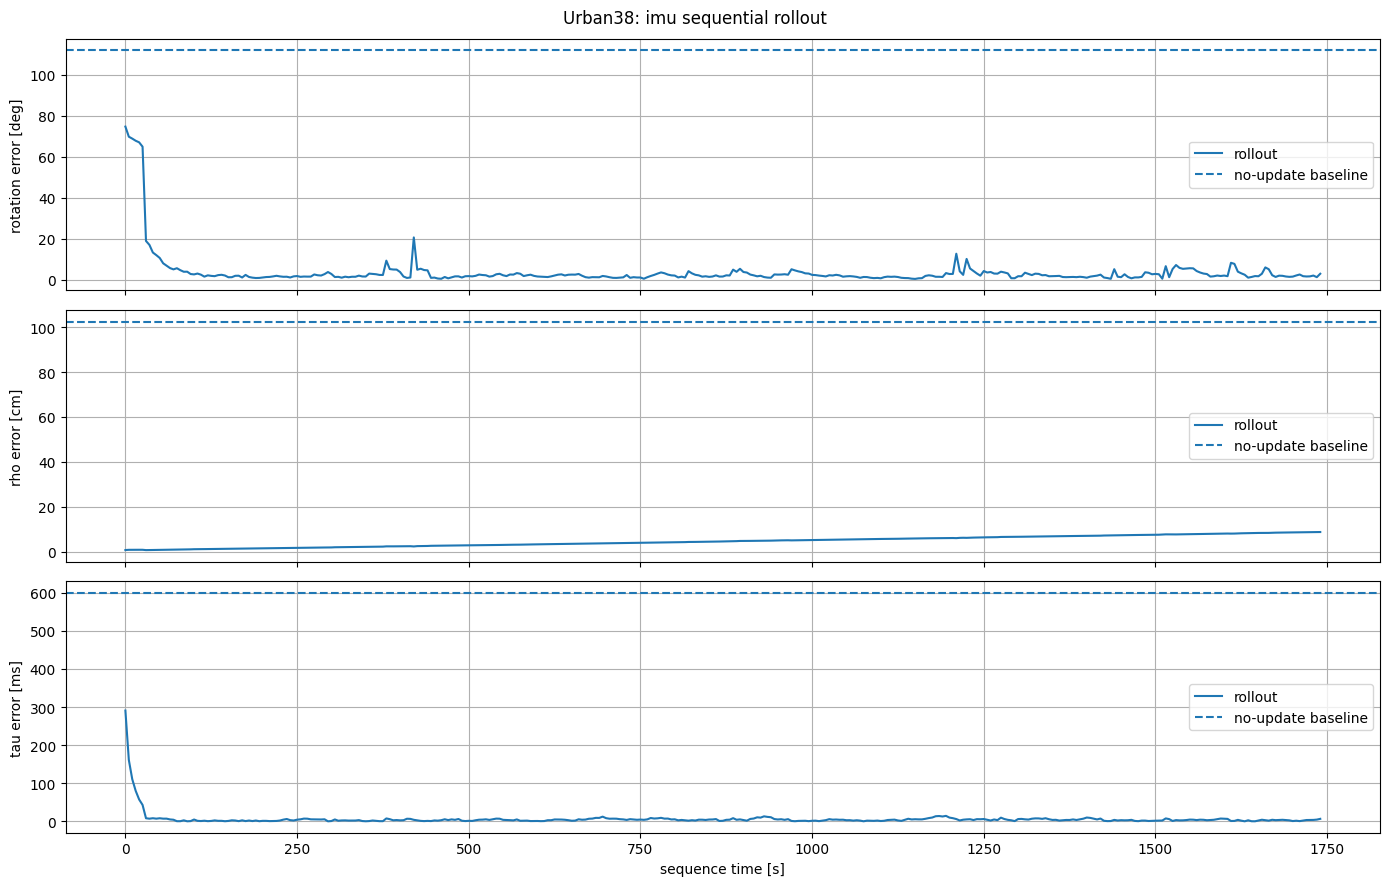

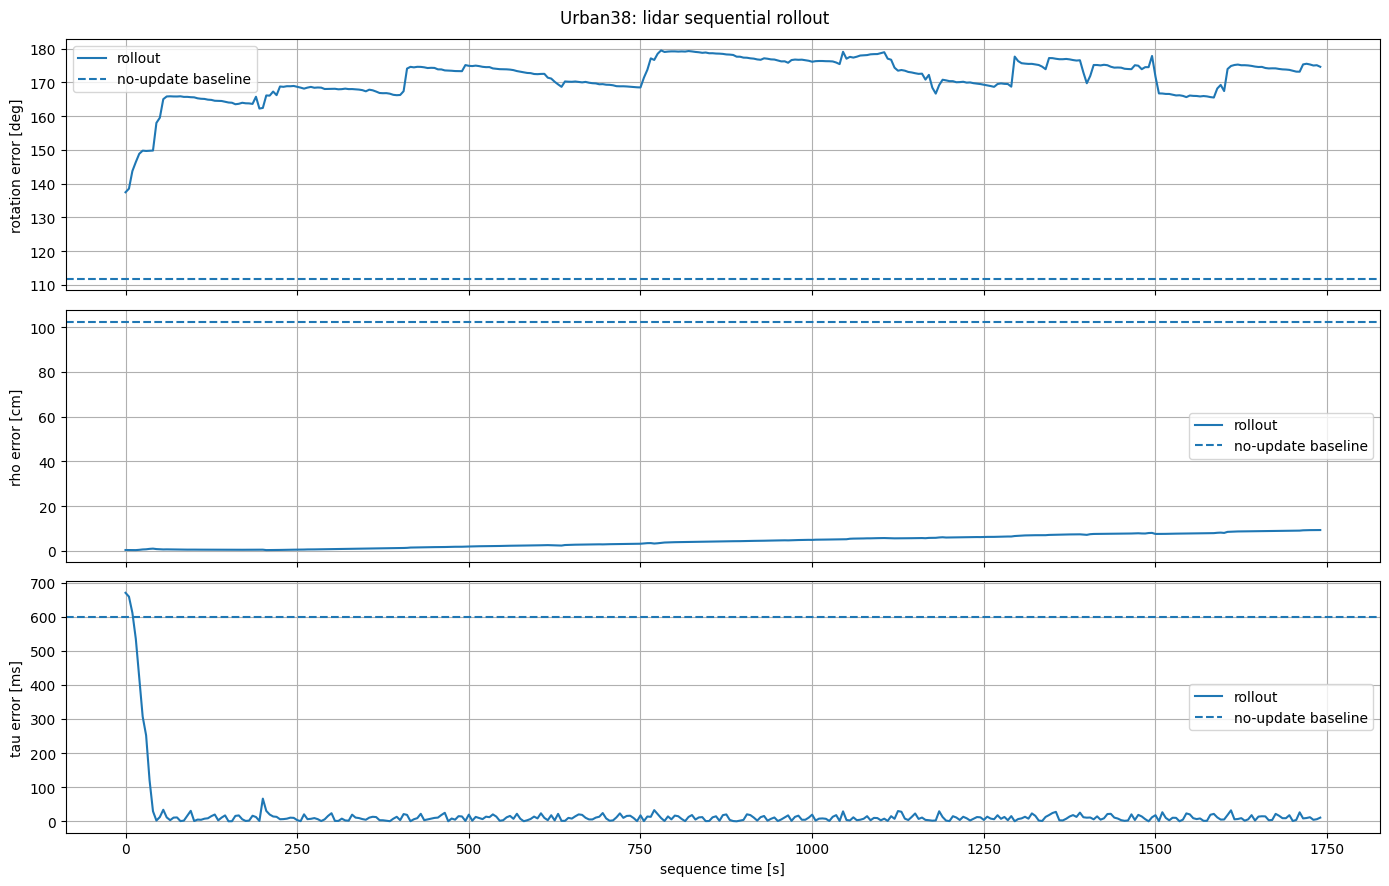

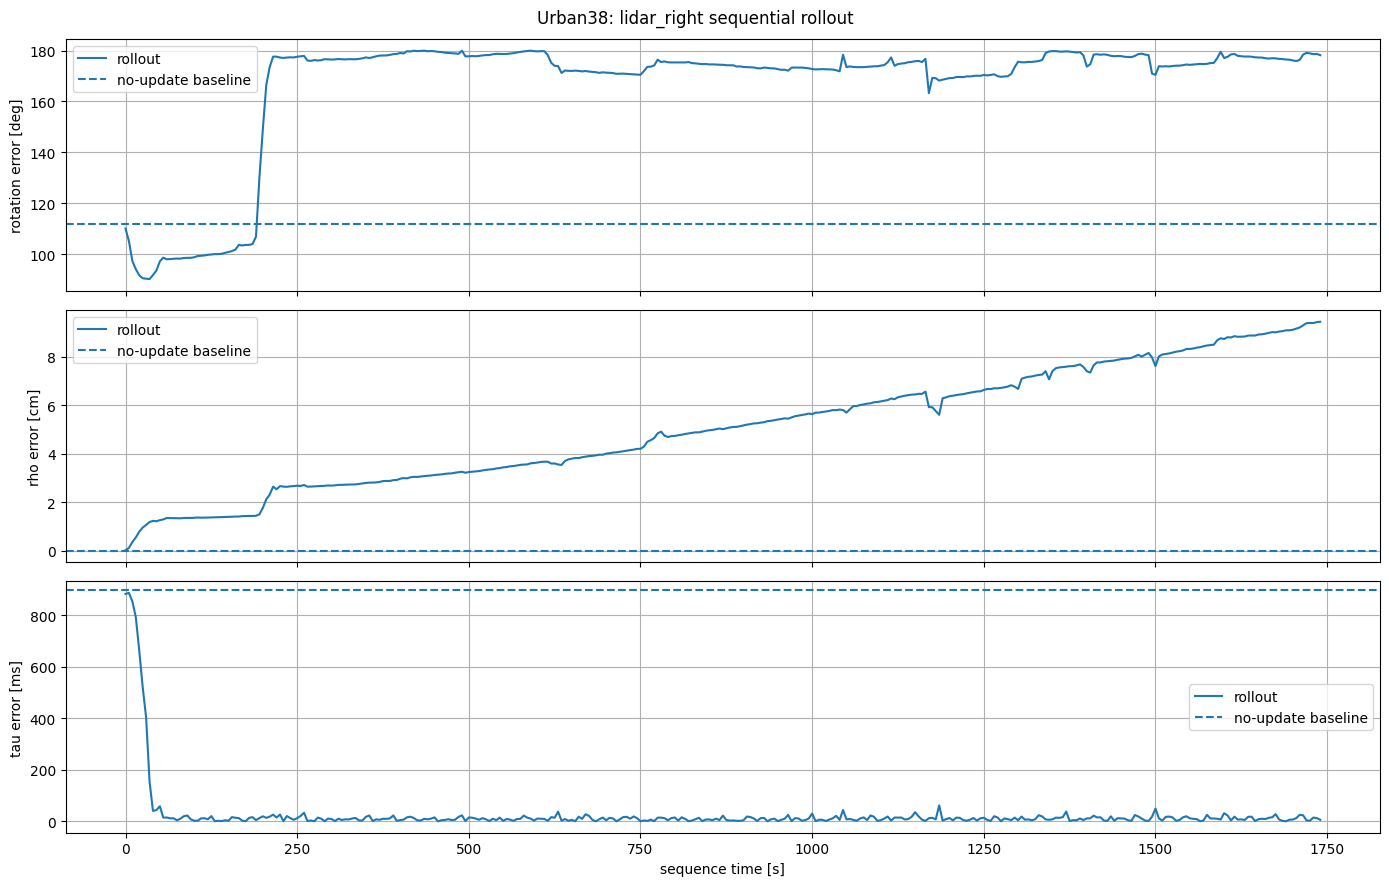

In [73]:
plot_rollout_error_norms(
    rollout_history,
    "imu",
)

plot_rollout_error_norms(
    rollout_history,
    "lidar",
)

plot_rollout_error_norms(
    rollout_history,
    "lidar_right",
)

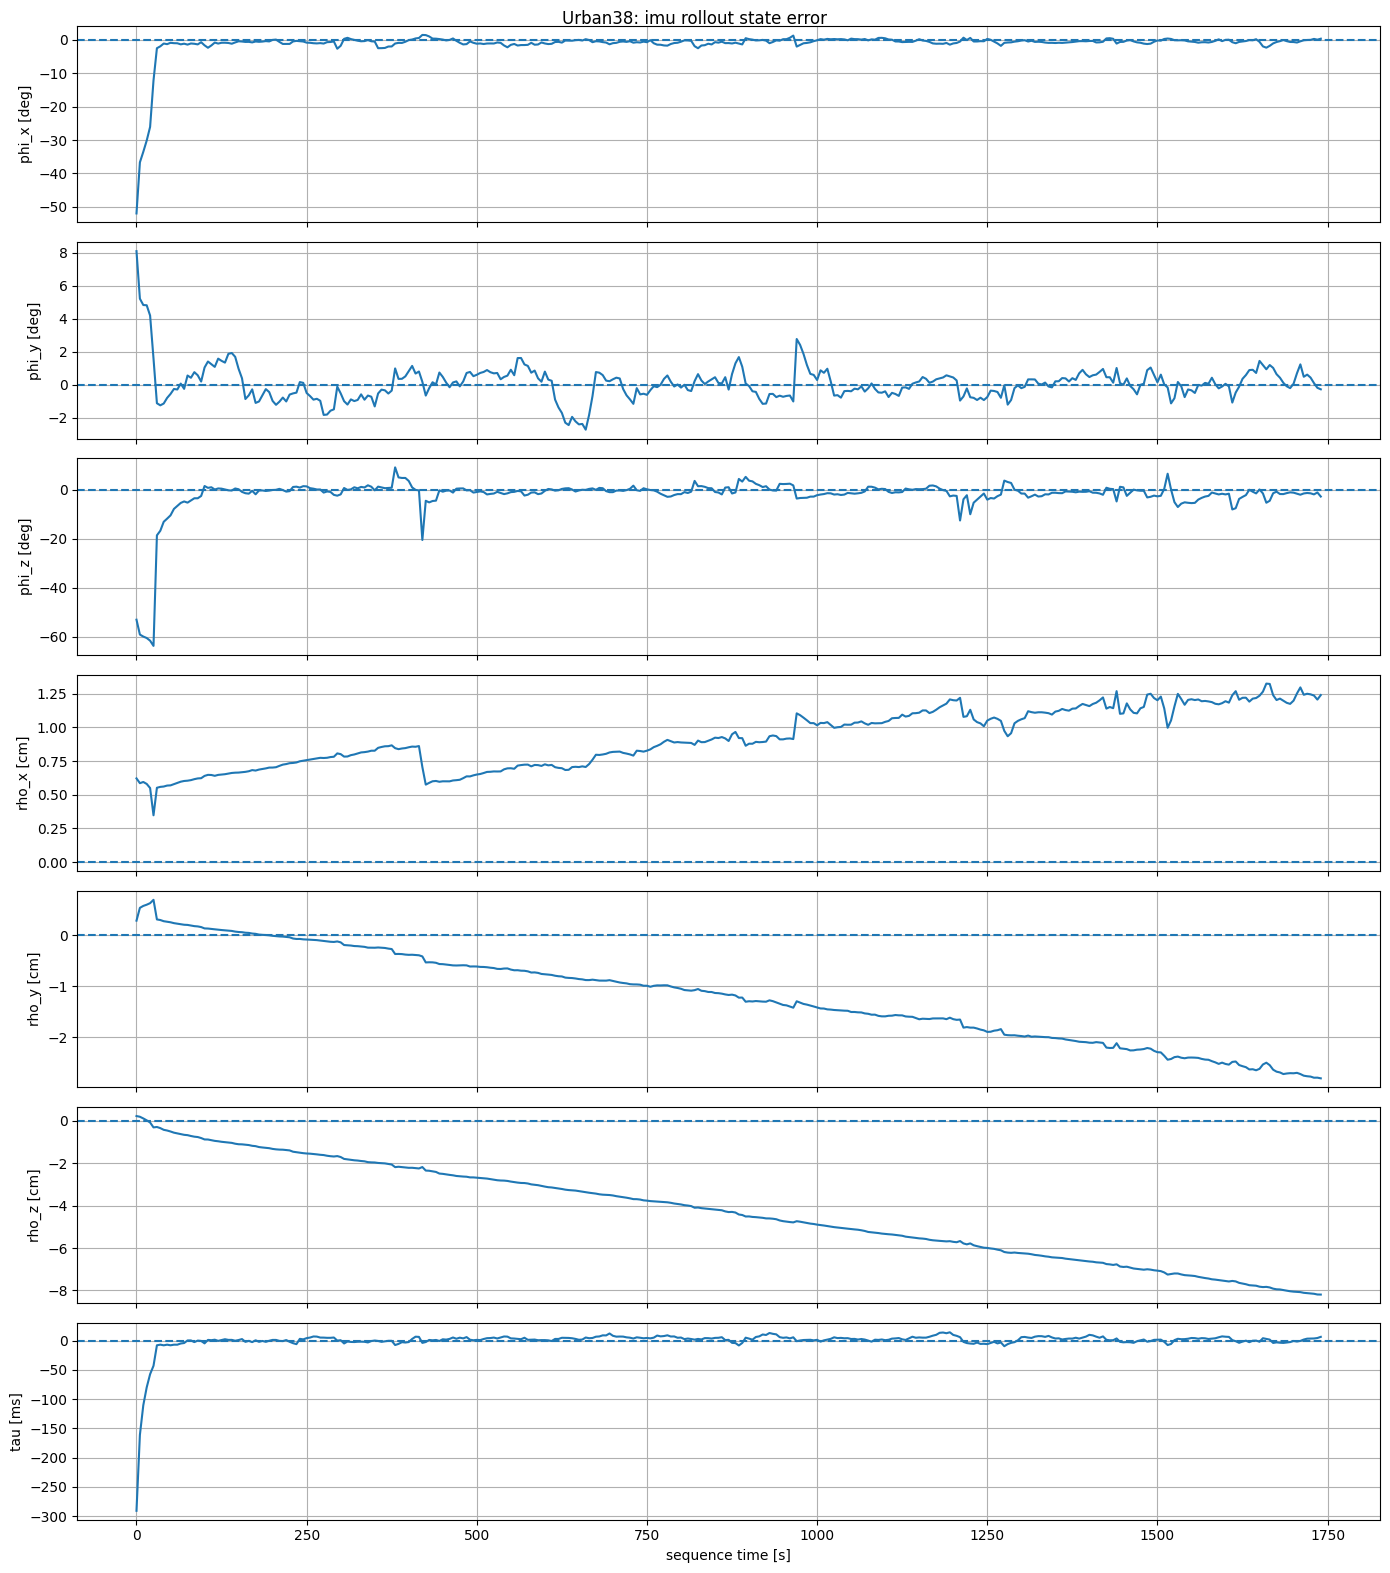

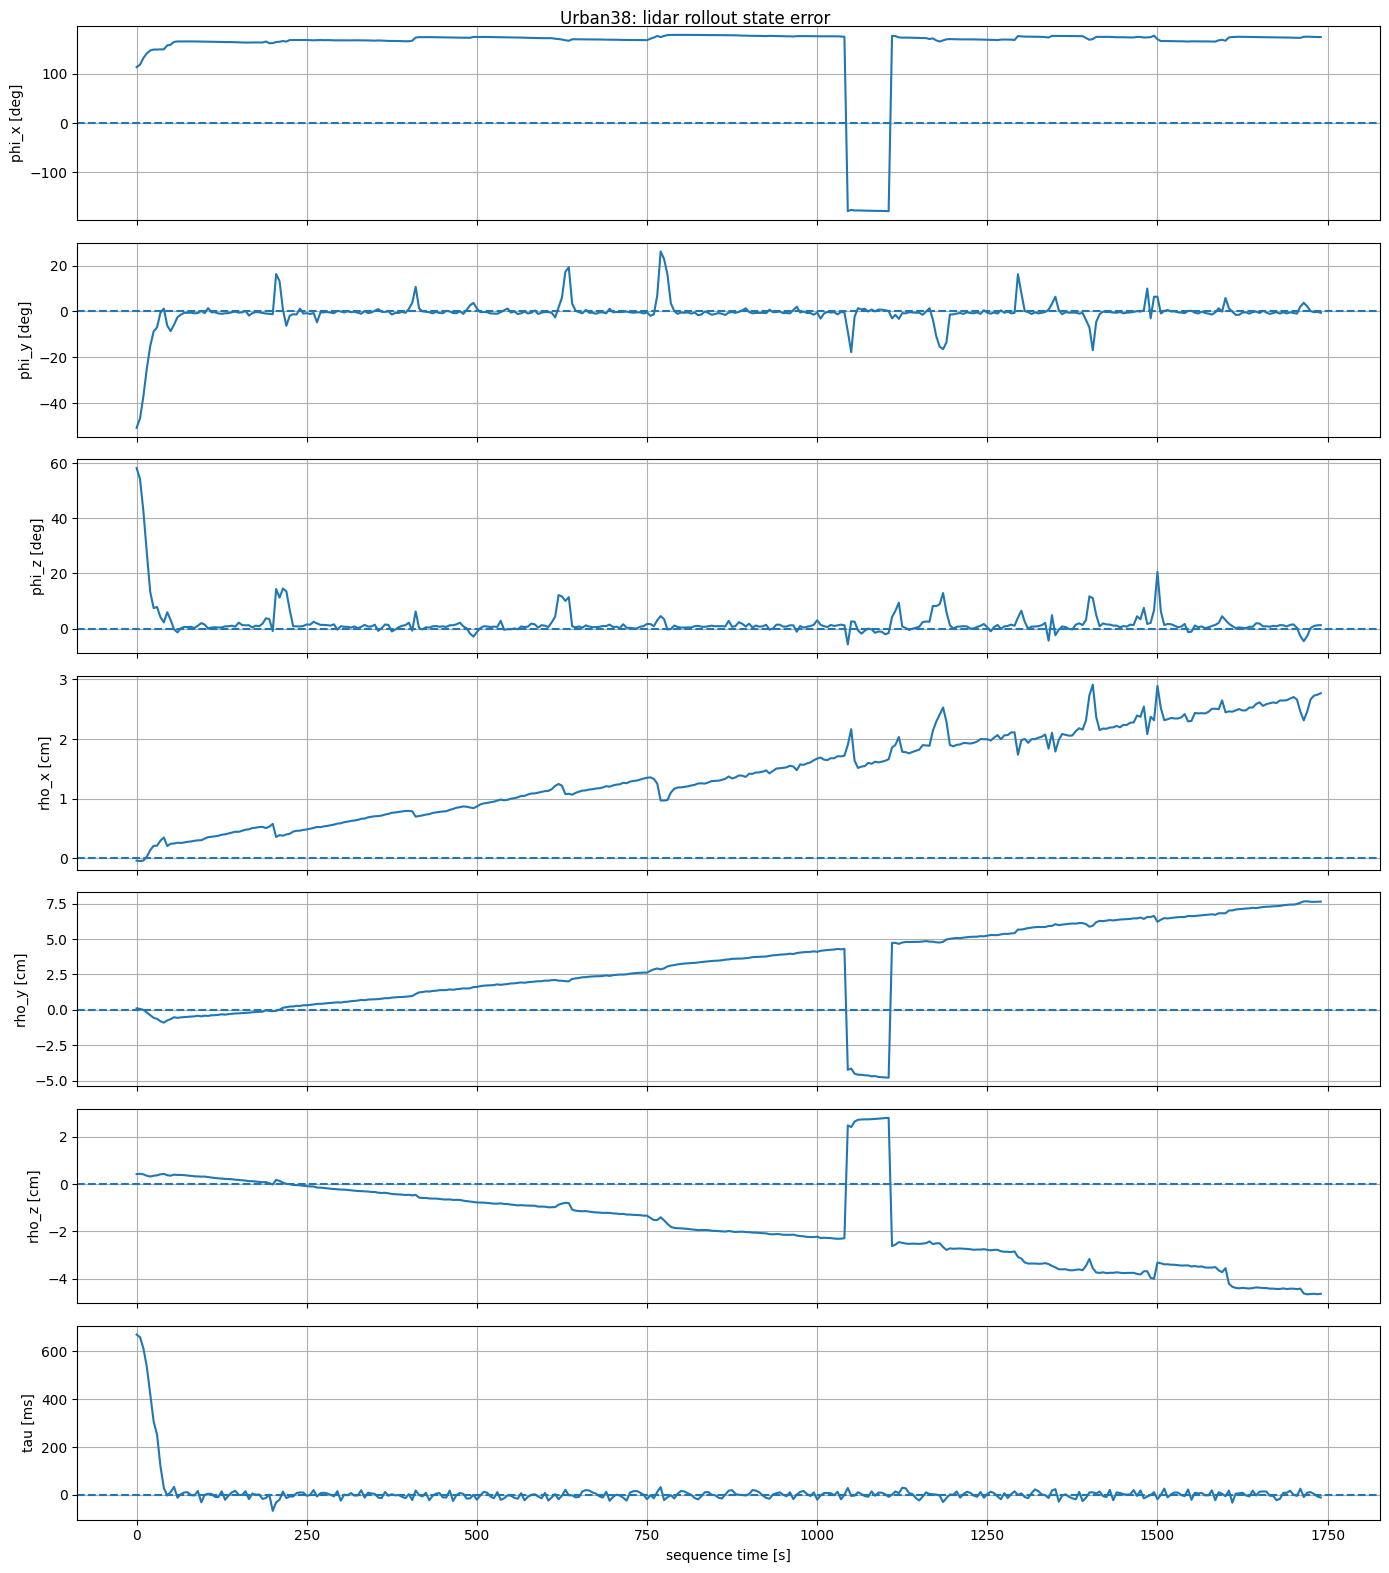

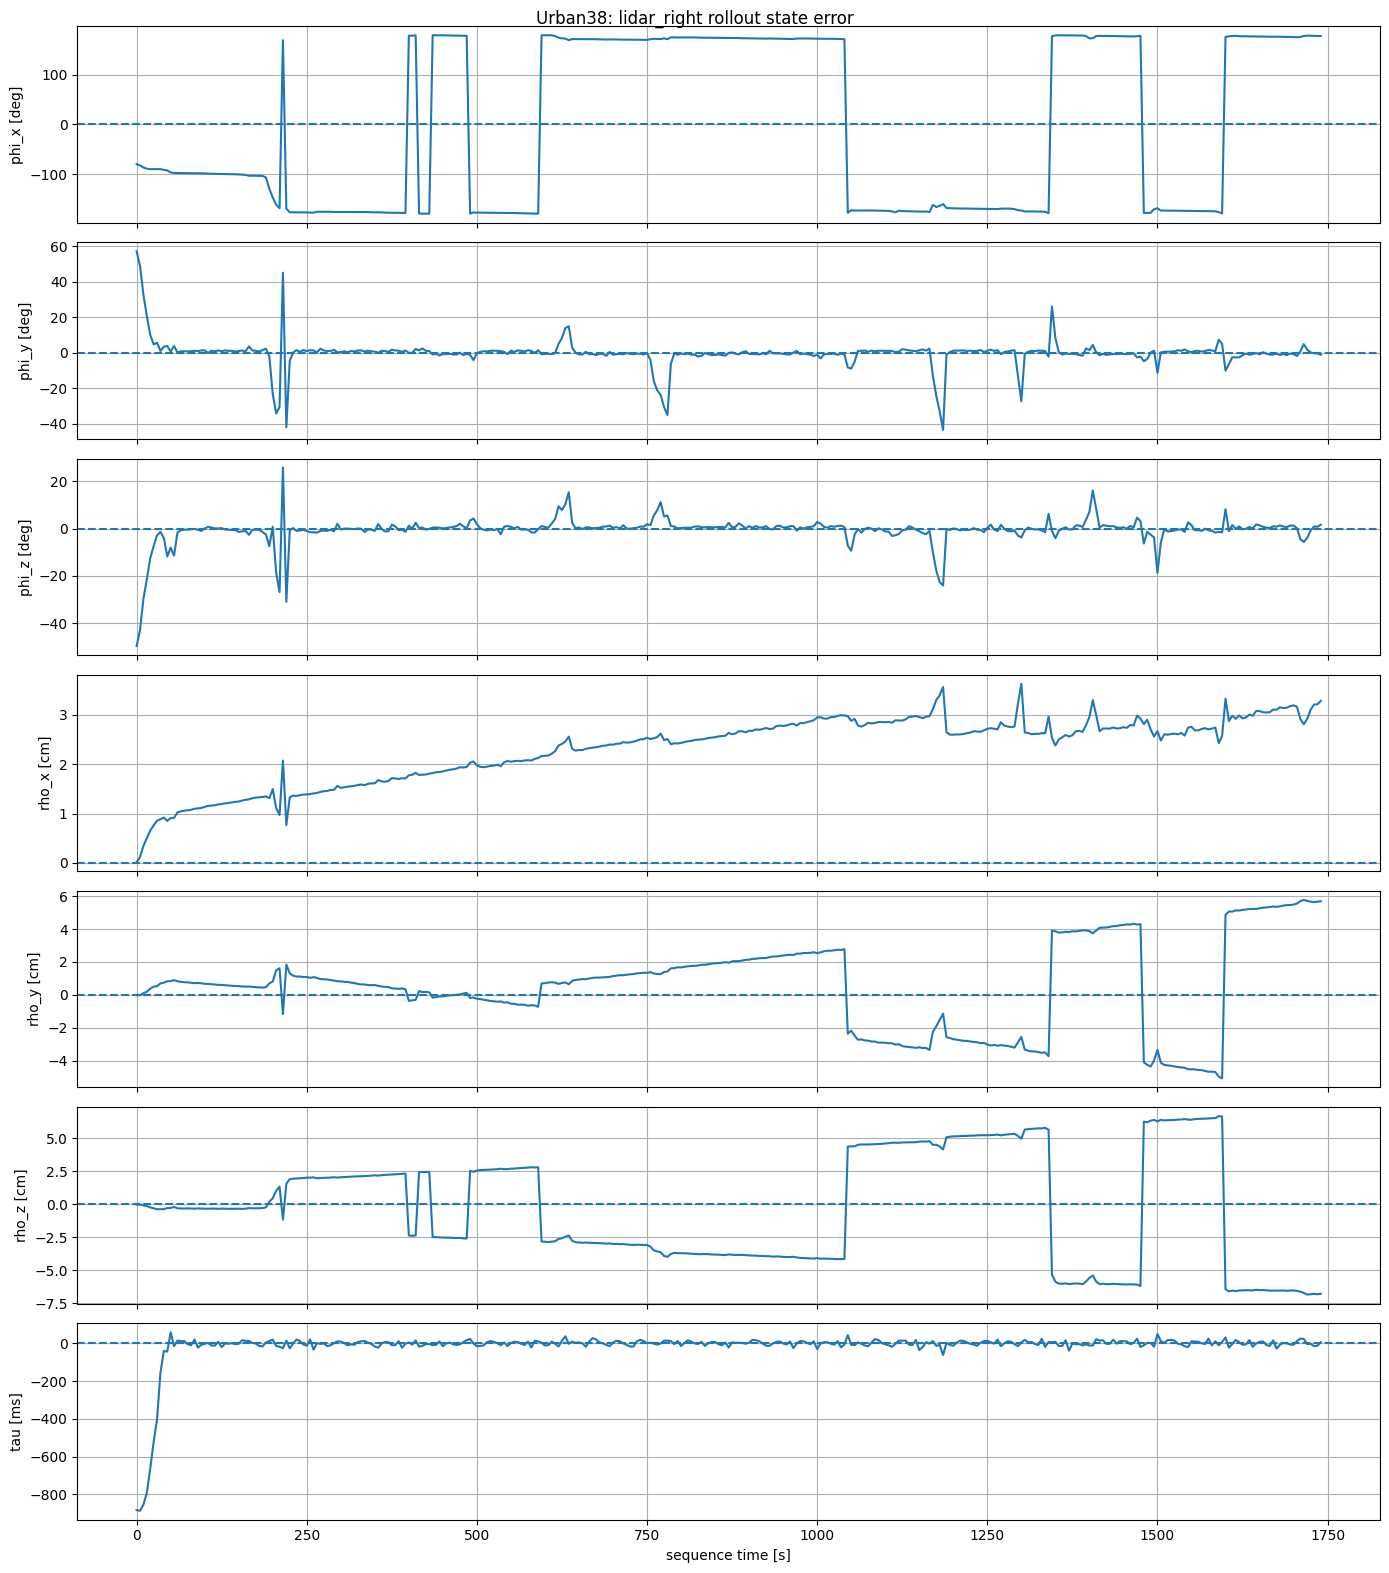

In [74]:
COMPONENT_NAMES = (
    "phi_x",
    "phi_y",
    "phi_z",
    "rho_x",
    "rho_y",
    "rho_z",
)


def plot_rollout_components(
    history,
    calibration_key,
):
    result = history[
        calibration_key
    ]

    error_xi = result[
        "error_after_xi"
    ]

    error_tau = result[
        "error_after_tau"
    ][:, 0]

    times_s = (
        np.arange(
            len(error_xi)
        )
        * windowing_config.window_stride_s
    )

    fig, axes = plt.subplots(
        7,
        1,
        figsize=(14, 16),
        sharex=True,
    )

    for component_index in range(3):
        axes[
            component_index
        ].plot(
            times_s,
            np.rad2deg(
                error_xi[
                    :,
                    component_index
                ]
            ),
        )

        axes[
            component_index
        ].axhline(
            0.0,
            linestyle="--",
        )

        axes[
            component_index
        ].set_ylabel(
            f"{COMPONENT_NAMES[component_index]} [deg]"
        )

        axes[
            component_index
        ].grid(True)

    for component_index in range(
        3,
        6,
    ):
        axes[
            component_index
        ].plot(
            times_s,
            100.0
            * error_xi[
                :,
                component_index
            ],
        )

        axes[
            component_index
        ].axhline(
            0.0,
            linestyle="--",
        )

        axes[
            component_index
        ].set_ylabel(
            f"{COMPONENT_NAMES[component_index]} [cm]"
        )

        axes[
            component_index
        ].grid(True)

    axes[-1].plot(
        times_s,
        1000.0 * error_tau,
    )

    axes[-1].axhline(
        0.0,
        linestyle="--",
    )

    axes[-1].set_ylabel(
        "tau [ms]"
    )

    axes[-1].set_xlabel(
        "sequence time [s]"
    )

    axes[-1].grid(True)

    fig.suptitle(
        f"{SEQUENCE_NAME}: {calibration_key} rollout state error"
    )

    fig.tight_layout()
    plt.show()

plot_rollout_components(
    rollout_history,
    "imu")
plot_rollout_components(
    rollout_history,
    "lidar")
plot_rollout_components(
    rollout_history,
    "lidar_right")

In [75]:
def plot_predicted_updates(
    history,
    calibration_key,
):
    result = history[
        calibration_key
    ]

    delta_xi = result[
        "predicted_delta_xi"
    ]

    delta_tau = result[
        "predicted_delta_tau"
    ][:, 0]

    event_probability = result[
        "event_probability"
    ][:, 0]

    times_s = (
        np.arange(
            len(delta_xi)
        )
        * windowing_config.window_stride_s
    )

    rotation_update_deg = np.rad2deg(
        np.linalg.norm(
            delta_xi[:, :3],
            axis=1,
        )
    )

    translation_update_cm = (
        100.0
        * np.linalg.norm(
            delta_xi[:, 3:],
            axis=1,
        )
    )

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(14, 10),
        sharex=True,
    )

    axes[0].plot(
        times_s,
        rotation_update_deg,
    )

    axes[0].set_ylabel(
        "|delta phi| [deg]"
    )

    axes[1].plot(
        times_s,
        translation_update_cm,
    )

    axes[1].set_ylabel(
        "|delta rho| [cm]"
    )

    axes[2].plot(
        times_s,
        1000.0 * delta_tau,
    )

    axes[2].set_ylabel(
        "delta tau [ms]"
    )

    axes[3].plot(
        times_s,
        event_probability,
    )

    axes[3].axhline(
        0.5,
        linestyle="--",
    )

    axes[3].set_ylabel(
        "event probability"
    )

    axes[3].set_xlabel(
        "sequence time [s]"
    )

    for axis in axes:
        axis.grid(True)

    fig.suptitle(
        f"{SEQUENCE_NAME}: {calibration_key} model updates"
    )

    fig.tight_layout()
    plt.show()

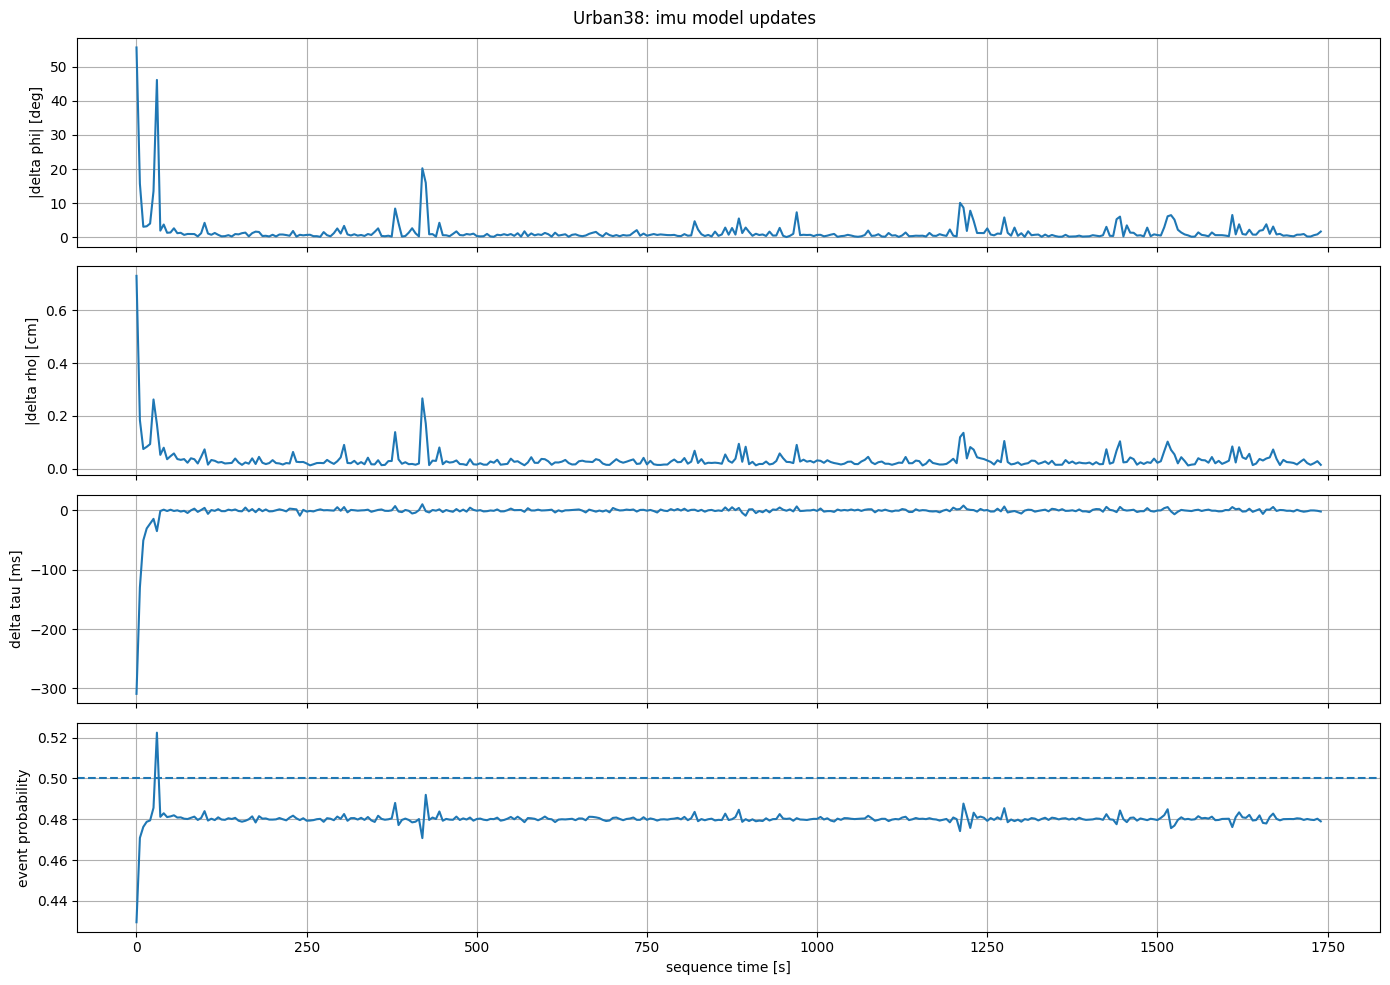

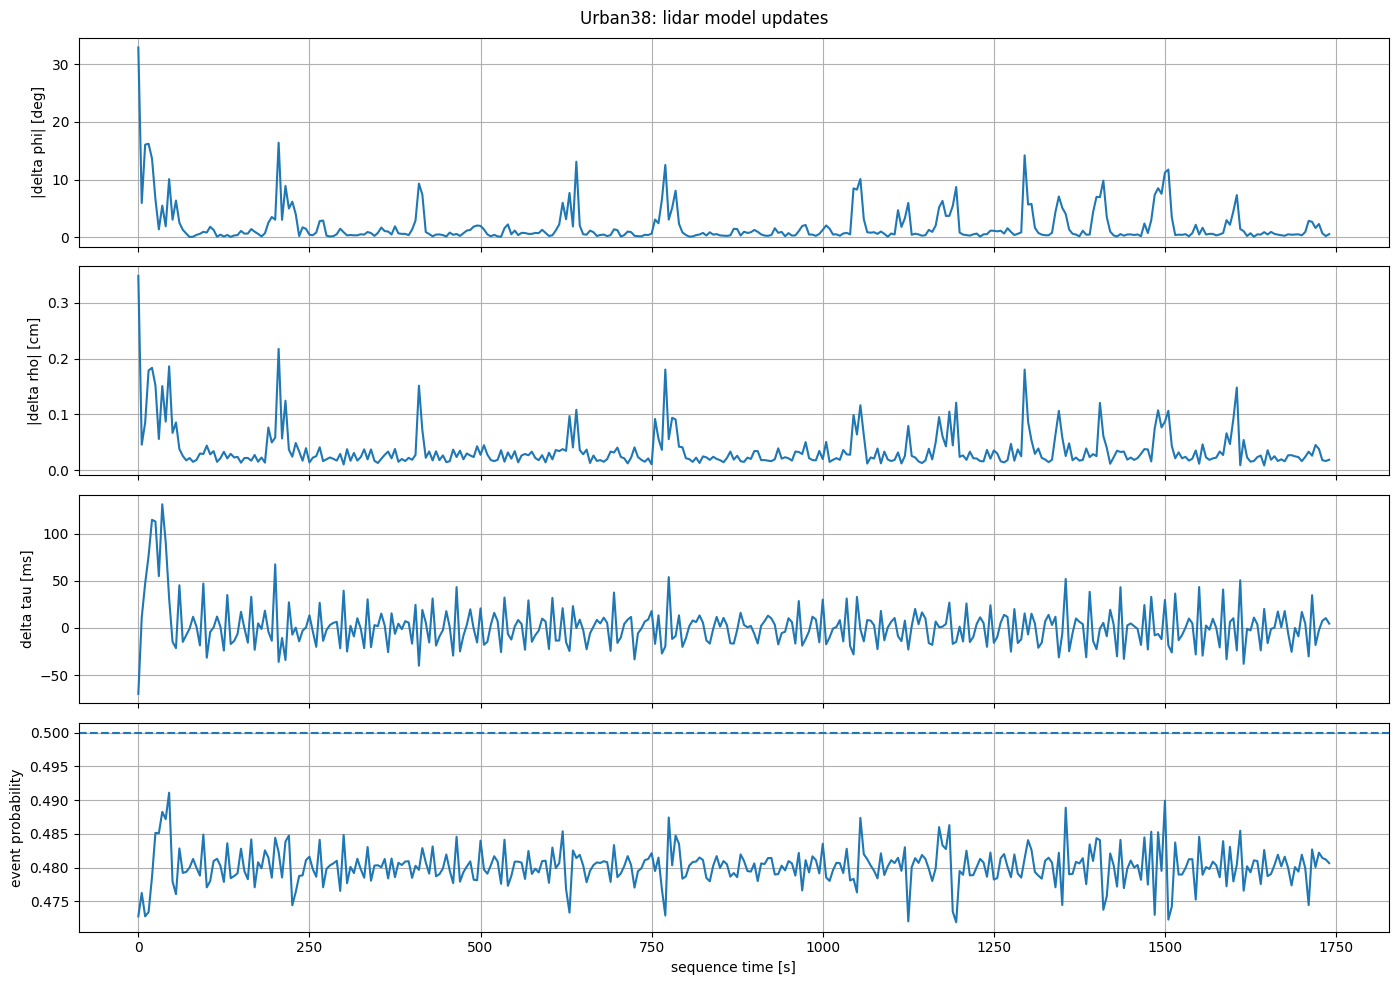

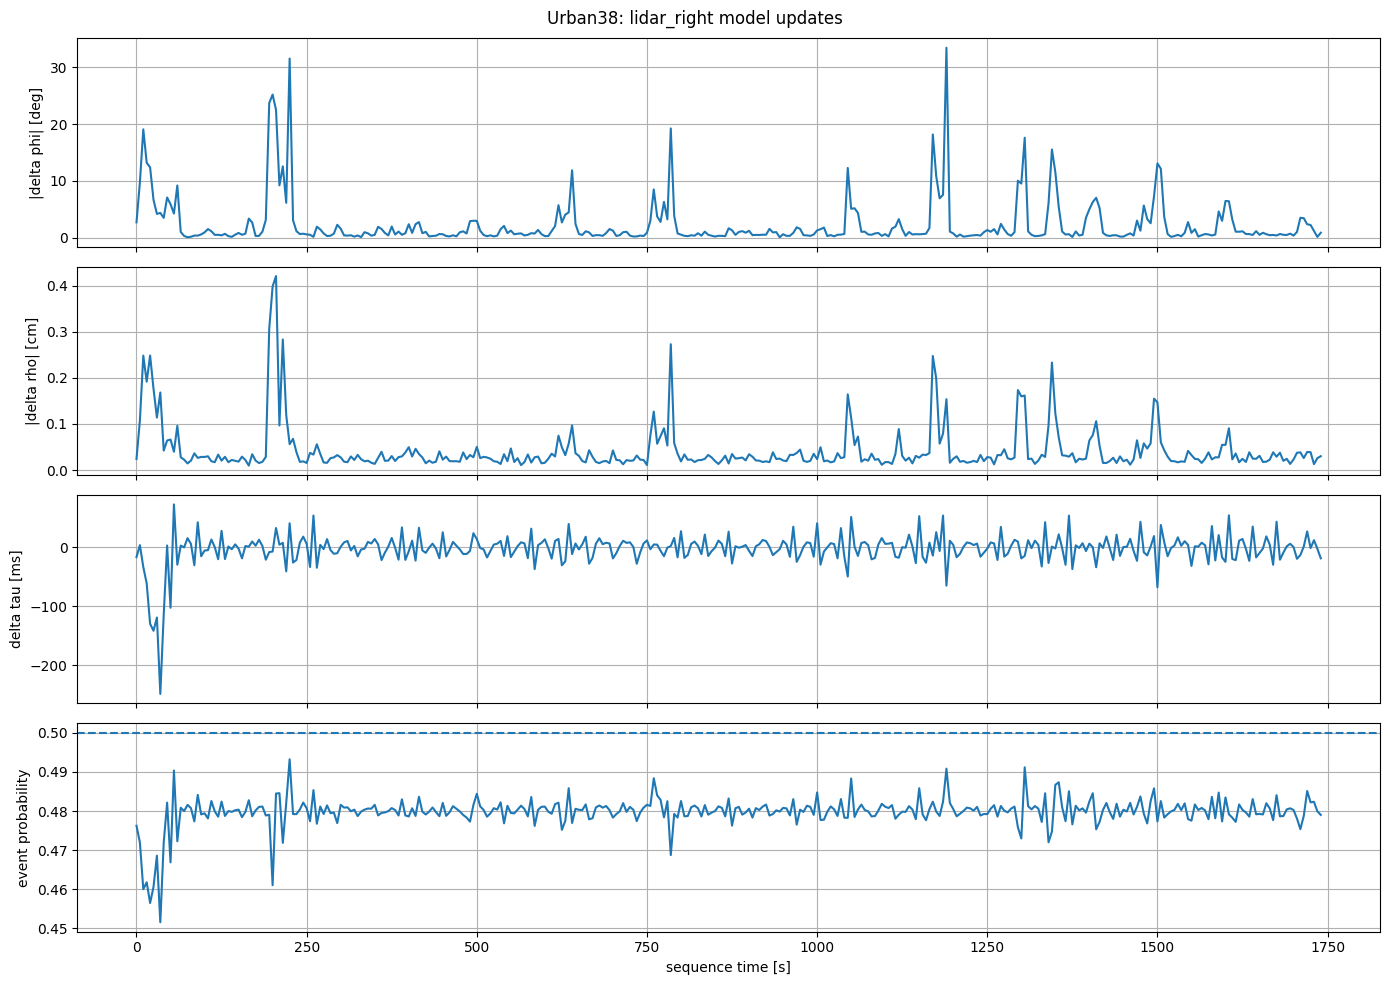

In [76]:

plot_predicted_updates(
    rollout_history,
    "imu")
plot_predicted_updates(
    rollout_history,
    "lidar")
plot_predicted_updates(
    rollout_history,
    "lidar_right")

NO-OBS MODEL: DIFFERENT WINDOWS AT IDENTICAL CALIBRATION
The current calibration supplied to the model is identical for every window.
Only the sensor measurements and timestamps change.

imu
component            mean             std           range
phi_x     -41.434620 deg    7.808424 deg   32.925148 deg
phi_y     +23.276129 deg    5.755658 deg   24.998425 deg
phi_z     +11.632255 deg    5.491651 deg   20.094807 deg
rho_x      -0.441979 cm     0.413810 cm     1.708673 cm 
rho_y      -0.193885 cm     0.189515 cm     0.748036 cm 
rho_z      -0.505615 cm     0.137137 cm     0.549289 cm 
tau      -261.647491 ms    73.503265 ms   253.140442 ms 

lidar
component            mean             std           range
phi_x     -25.519506 deg   11.805901 deg   43.611591 deg
phi_y      +8.806330 deg    6.812050 deg   32.082447 deg
phi_z     +10.400190 deg    7.218169 deg   27.432192 deg
rho_x      -0.269900 cm     0.335745 cm     1.316491 cm 
rho_y      -0.182128 cm     0.133829 cm     0.634482 cm 
rh

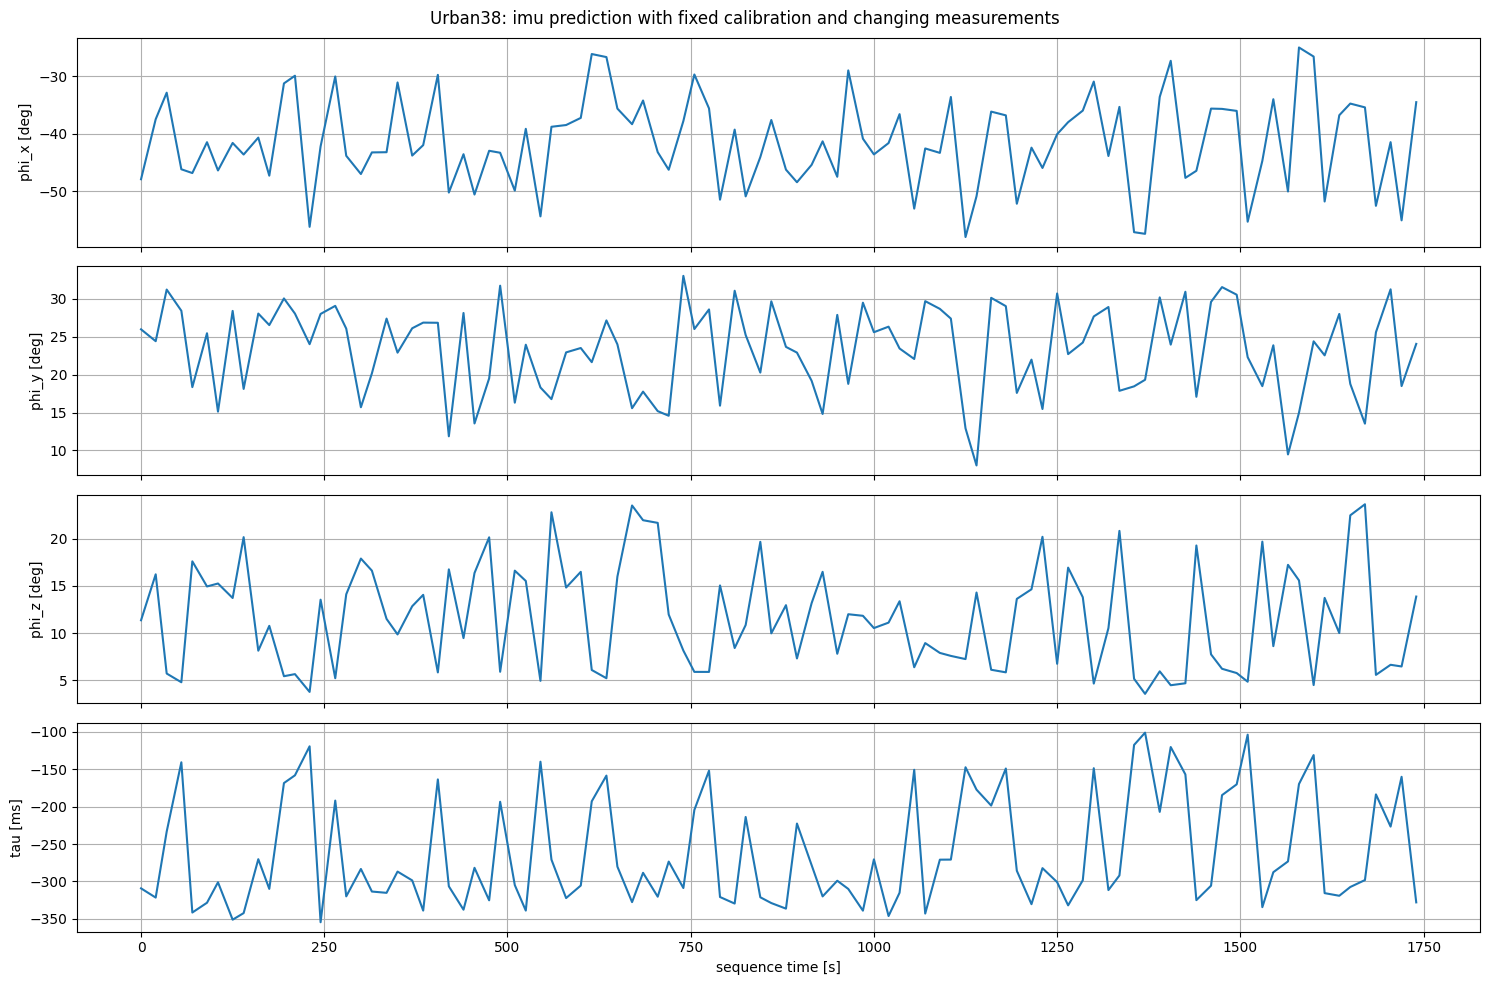

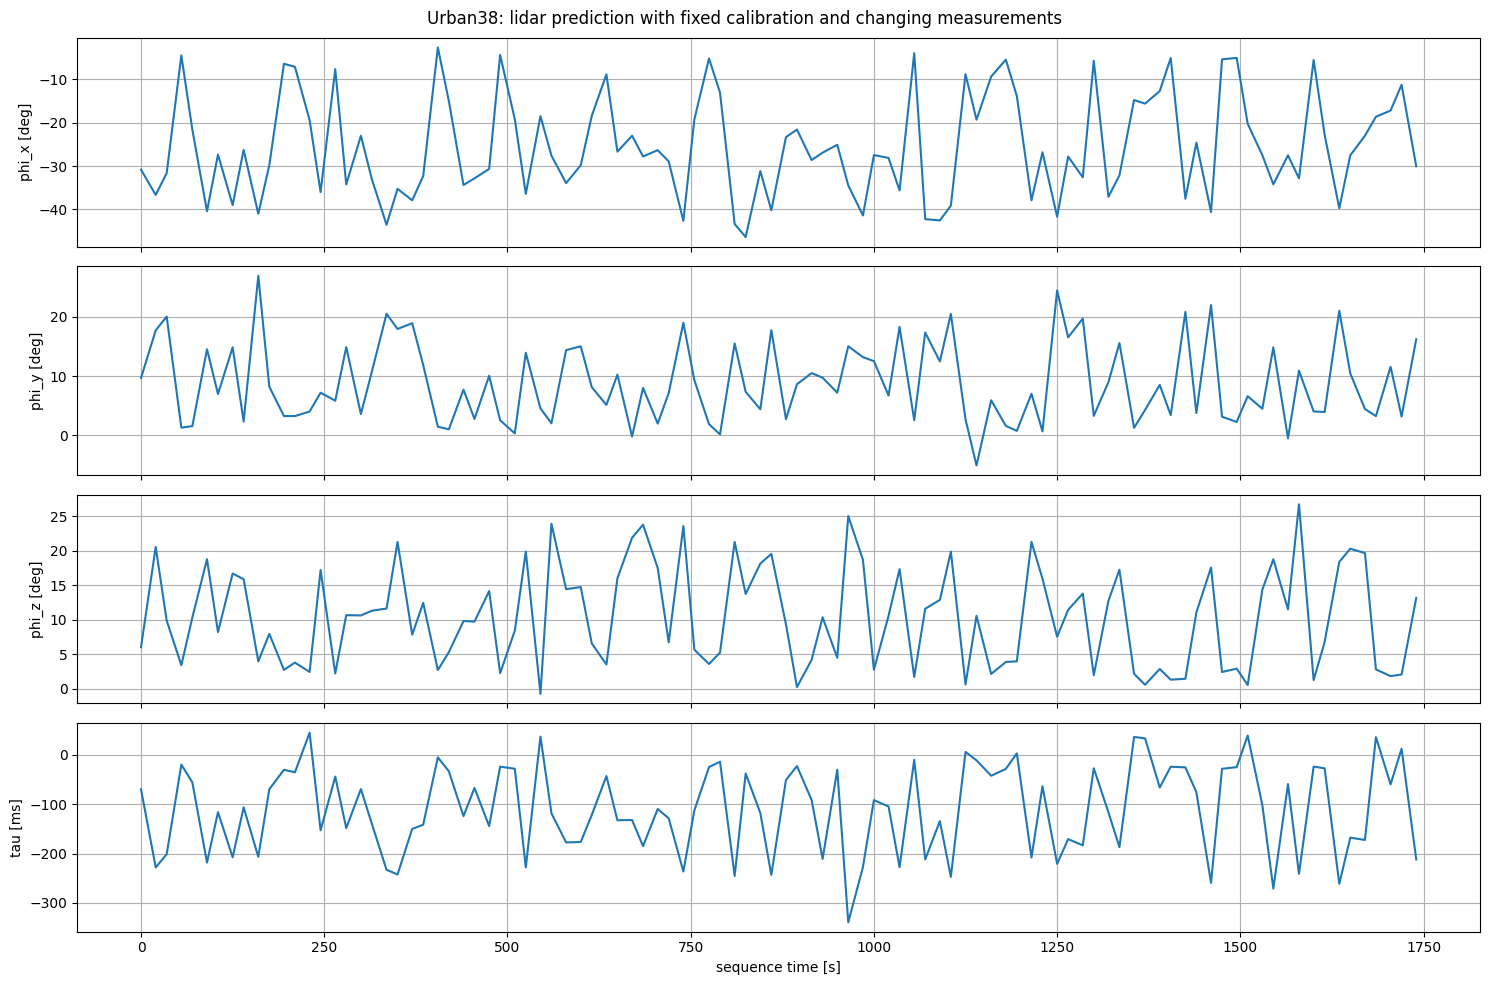

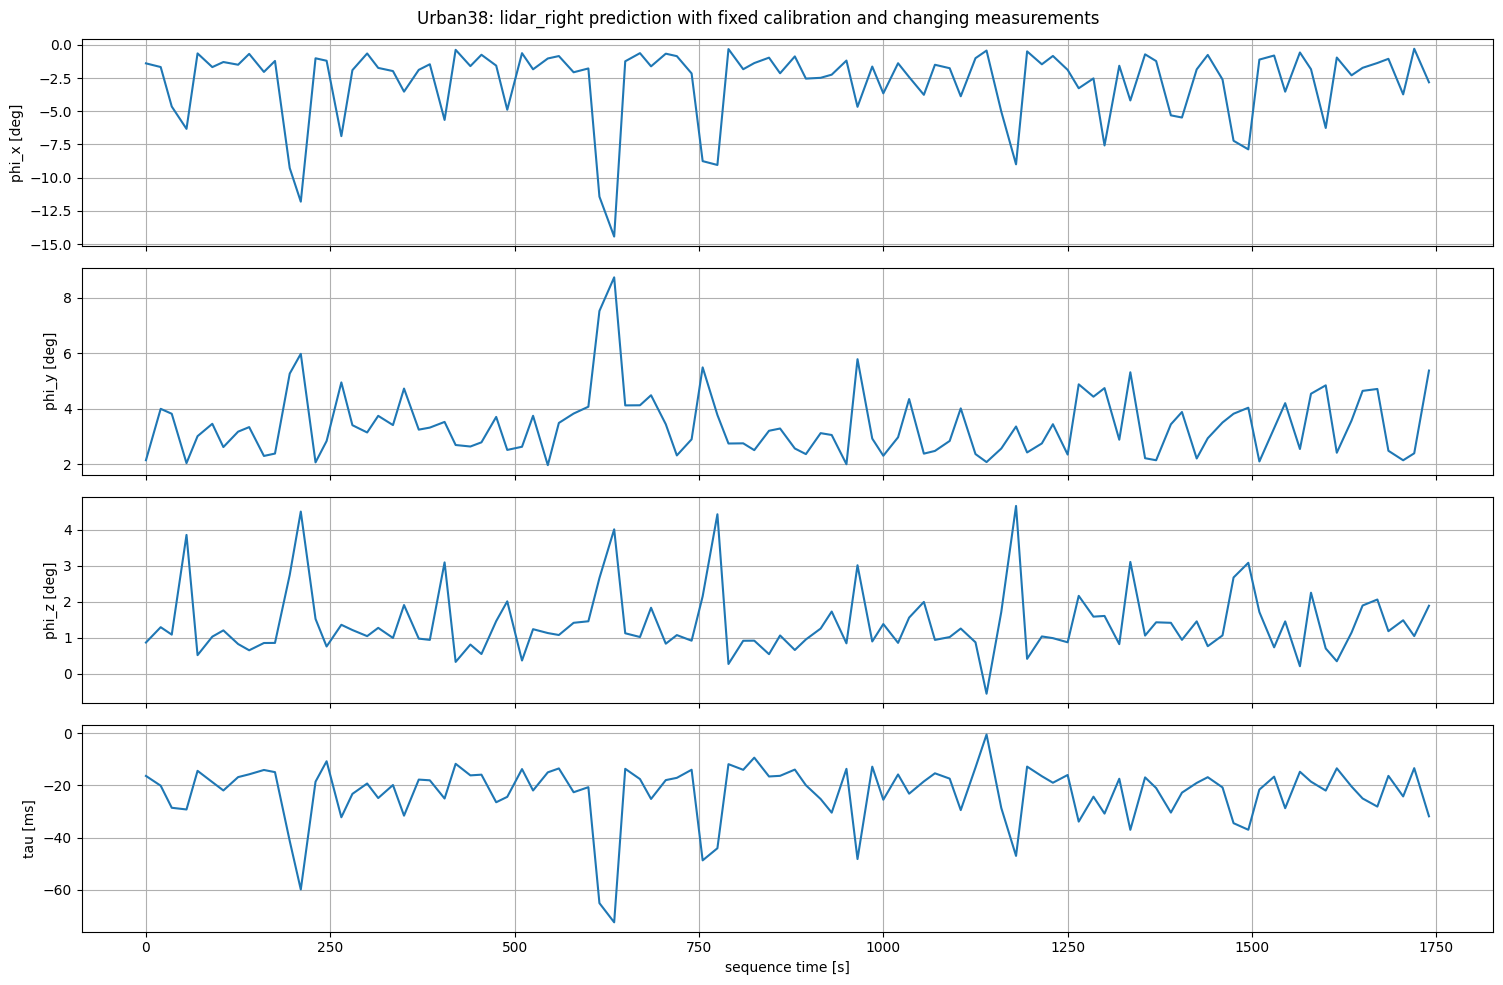

In [77]:
##################################################
# Measurement sensitivity at fixed calibration
##################################################

FIXED_CALIBRATION_NUM_WINDOWS = min(100, len(rollout_indices))

selected_positions = np.unique(np.linspace(0, len(rollout_indices) - 1, FIXED_CALIBRATION_NUM_WINDOWS).round().astype(int))
sensitivity_indices = np.asarray(rollout_indices)[selected_positions]

fixed_calibration_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in sensitivity_indices:
        window = window_batch_to(collate_windows([rollout_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        result = window_step(window, calibration=initial_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_calibration_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_calibration_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in fixed_calibration_results:
    fixed_calibration_results[calibration_key]["delta_xi"] = torch.stack(fixed_calibration_results[calibration_key]["delta_xi"]).numpy()
    fixed_calibration_results[calibration_key]["delta_tau"] = torch.stack(fixed_calibration_results[calibration_key]["delta_tau"]).numpy()

##################################################
# Numerical summary
##################################################

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 110)
print("NO-OBS MODEL: DIFFERENT WINDOWS AT IDENTICAL CALIBRATION")
print("=" * 110)
print("The current calibration supplied to the model is identical for every window.")
print("Only the sensor measurements and timestamps change.")
print()

for calibration_key in CALIBRATION_KEYS:
    result = fixed_calibration_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>15s} {'std':>15s} {'range':>15s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        print(f"{component_name:8s} {values.mean():+11.6f} {unit:3s} {values.std():11.6f} {unit:3s} {(values.max() - values.min()):11.6f} {unit:3s}")

    print()

##################################################
# Plot
##################################################

times_s = selected_positions * windowing_config.window_stride_s
plot_components = (("phi_x", 0), ("phi_y", 1), ("phi_z", 2), ("tau", 6))

for calibration_key in CALIBRATION_KEYS:
    result = fixed_calibration_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    fig, axes = plt.subplots(len(plot_components), 1, figsize=(15, 10), sharex=True)

    for axis, (component_name, component_index) in zip(axes, plot_components):
        if component_index < 3:
            values, unit = np.rad2deg(prediction[:, component_index]), "deg"
        else:
            values, unit = 1000.0 * prediction[:, component_index], "ms"

        axis.plot(times_s, values)
        axis.set_ylabel(f"{component_name} [{unit}]")
        axis.grid(True)

    axes[-1].set_xlabel("sequence time [s]")
    fig.suptitle(f"{SEQUENCE_NAME}: {calibration_key} prediction with fixed calibration and changing measurements")
    fig.tight_layout()
    plt.show()

In [78]:
##################################################
# Locate where measurement dependence disappears
##################################################

FEATURE_DIAGNOSTIC_NUM_WINDOWS = min(100, len(rollout_indices))
selected_positions = np.unique(np.linspace(0, len(rollout_indices) - 1, FEATURE_DIAGNOSTIC_NUM_WINDOWS).round().astype(int))
feature_indices = np.asarray(rollout_indices)[selected_positions]

shared_features = []
summary_features = []

model.eval()

with torch.no_grad():
    for dataset_index in feature_indices:
        window = window_batch_to(collate_windows([rollout_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)

        canonical_streams = geometry_processor(window.streams, window.metadata, initial_calibration)
        tokens = tokenizer(canonical_streams, None)

        transformer_output = model.transformer_encoder(tokens)
        flattened_summaries = transformer_output.summary_features.flatten(start_dim=1)
        shared = model.mlp_body(flattened_summaries)

        summary_features.append(flattened_summaries[0].cpu())
        shared_features.append(shared[0].cpu())

summary_features = torch.stack(summary_features).numpy()
shared_features = torch.stack(shared_features).numpy()

print("=" * 90)
print("MEASUREMENT-DEPENDENCE INSIDE MODEL")
print("=" * 90)
print("summary feature mean std across dimensions:", np.std(summary_features, axis=0).mean())
print("summary feature max std across dimensions:", np.std(summary_features, axis=0).max())
print("shared feature mean std across dimensions:", np.std(shared_features, axis=0).mean())
print("shared feature max std across dimensions:", np.std(shared_features, axis=0).max())
print("mean pairwise change between consecutive shared features:", np.mean(np.linalg.norm(np.diff(shared_features, axis=0), axis=1)))

MEASUREMENT-DEPENDENCE INSIDE MODEL
summary feature mean std across dimensions: 0.24551581
summary feature max std across dimensions: 0.88207185
shared feature mean std across dimensions: 0.038112614
shared feature max std across dimensions: 0.1292361
mean pairwise change between consecutive shared features: 0.5971182


In [79]:
##################################################
# Counterfactual calibration test
#
# Same real motion window.
# Same numerical calibration prior supplied to the model.
# Opposite true sensor rotations and consistently re-expressed measurements.
#
# If the model uses measurement evidence, predicted corrections should
# distinguish +ANGLE from -ANGLE.
##################################################

from obscalib.data.structures import GeometryType, SensorStreamBatch, WindowBatch
from obscalib.geometry.lie import so3_exp

COUNTERFACTUAL_DATASET_INDEX = rollout_indices[0]
COUNTERFACTUAL_ROTATION_DEG = 20.0

counterfactual_base_window = window_batch_to(
    collate_windows([rollout_dataset[int(COUNTERFACTUAL_DATASET_INDEX)]]),
    DEVICE,
    dtype=MODEL_DTYPE,
)

# The same numerical prior will be supplied in every counterfactual case.
counterfactual_prior = {
    calibration_key: CalibrationState(
        transform=state.transform.clone(),
        time_offset=state.time_offset.clone(),
    )
    for calibration_key, state in counterfactual_base_window.current_calibration.items()
}


def make_rotation_only_se3(rotation):
    transform = torch.zeros(
        rotation.shape[:-2] + (4, 4),
        dtype=rotation.dtype,
        device=rotation.device,
    )
    transform[..., :3, :3] = rotation
    transform[..., 3, 3] = 1.0
    return transform


def reexpress_stream_for_true_rotation(stream, geometry_type, relative_rotation):
    """
    Re-express the raw stream after changing the true sensor orientation.

    relative_rotation = R_old.T @ R_new
    """

    values = stream.values.clone()

    if geometry_type == GeometryType.VECTOR:
        values = values @ relative_rotation

    elif geometry_type == GeometryType.SO3:
        values = relative_rotation.transpose(-1, -2)[:, None] @ values @ relative_rotation[:, None]

    elif geometry_type == GeometryType.SE3:
        relative_transform = make_rotation_only_se3(relative_rotation)
        inverse_relative_transform = torch.linalg.inv(relative_transform)
        values = inverse_relative_transform[:, None] @ values @ relative_transform[:, None]

    else:
        raise ValueError(f"Unsupported geometry type: {geometry_type!r}")

    return SensorStreamBatch(
        values=values,
        timestamps=stream.timestamps.clone(),
        sample_mask=stream.sample_mask.clone(),
        interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.clone(),
    )


def make_counterfactual_true_rotation_window(base_window, calibration_key, delta_phi):
    """
    Change one sensor's true rotation while preserving its translation and tau.

    R_true_new = Exp(delta_phi) @ R_true_old

    Streams belonging to that calibration key are re-expressed consistently.
    """

    old_state = base_window.current_calibration[calibration_key]

    delta_rotation = so3_exp(delta_phi)
    new_transform = old_state.transform.clone()
    new_transform[..., :3, :3] = delta_rotation @ old_state.transform[..., :3, :3]

    new_state = CalibrationState(
        transform=new_transform,
        time_offset=old_state.time_offset.clone(),
    )

    new_calibration = {
        key: CalibrationState(
            transform=state.transform.clone(),
            time_offset=state.time_offset.clone(),
        )
        for key, state in base_window.current_calibration.items()
    }
    new_calibration[calibration_key] = new_state

    relative_rotation = (
        old_state.transform[..., :3, :3].transpose(-1, -2)
        @ new_transform[..., :3, :3]
    )

    new_streams = {}

    for stream_key, stream in base_window.streams.items():
        metadata = base_window.metadata[stream_key]

        if metadata.calibration_key == calibration_key:
            new_streams[stream_key] = reexpress_stream_for_true_rotation(
                stream,
                metadata.geometry_type,
                relative_rotation,
            )
        else:
            new_streams[stream_key] = SensorStreamBatch(
                values=stream.values.clone(),
                timestamps=stream.timestamps.clone(),
                sample_mask=stream.sample_mask.clone(),
                interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps.clone(),
            )

    counterfactual_window = WindowBatch(
        streams=new_streams,
        current_calibration=new_calibration,
        metadata=dict(base_window.metadata),
        targets=None,
        dataset_indices=base_window.dataset_indices,
    )

    return counterfactual_window, new_state


##################################################
# Run +/- rotation around each coordinate axis
##################################################

axis_names = ("x", "y", "z")
angle_rad = np.deg2rad(COUNTERFACTUAL_ROTATION_DEG)

model.eval()

print("=" * 120)
print("COUNTERFACTUAL TEST: SAME PRIOR, OPPOSITE TRUE CALIBRATION")
print("=" * 120)
print(f"dataset window: {COUNTERFACTUAL_DATASET_INDEX}")
print(f"rotation magnitude: {COUNTERFACTUAL_ROTATION_DEG:.1f} deg")
print()

with torch.no_grad():
    for calibration_key in CALIBRATION_KEYS:
        print(calibration_key)
        print("-" * 120)

        for axis_index, axis_name in enumerate(axis_names):
            delta_phi_positive = torch.zeros(1, 3, dtype=MODEL_DTYPE, device=DEVICE)
            delta_phi_negative = torch.zeros(1, 3, dtype=MODEL_DTYPE, device=DEVICE)

            delta_phi_positive[0, axis_index] = angle_rad
            delta_phi_negative[0, axis_index] = -angle_rad

            positive_window, positive_truth = make_counterfactual_true_rotation_window(
                counterfactual_base_window,
                calibration_key,
                delta_phi_positive,
            )

            negative_window, negative_truth = make_counterfactual_true_rotation_window(
                counterfactual_base_window,
                calibration_key,
                delta_phi_negative,
            )

            positive_result = window_step(
                positive_window,
                calibration=counterfactual_prior,
            )

            negative_result = window_step(
                negative_window,
                calibration=counterfactual_prior,
            )

            positive_prediction = positive_result.model_output.predictions[calibration_key].delta_xi[0, :3]
            negative_prediction = negative_result.model_output.predictions[calibration_key].delta_xi[0, :3]

            prior_state = counterfactual_prior[calibration_key]

            positive_target = se3_log(
                positive_truth.transform
                @ torch.linalg.inv(prior_state.transform)
            )[0, :3]

            negative_target = se3_log(
                negative_truth.transform
                @ torch.linalg.inv(prior_state.transform)
            )[0, :3]

            positive_prediction_deg = torch.rad2deg(positive_prediction).cpu().numpy()
            negative_prediction_deg = torch.rad2deg(negative_prediction).cpu().numpy()
            positive_target_deg = torch.rad2deg(positive_target).cpu().numpy()
            negative_target_deg = torch.rad2deg(negative_target).cpu().numpy()

            prediction_separation_deg = np.linalg.norm(
                positive_prediction_deg - negative_prediction_deg
            )

            target_separation_deg = np.linalg.norm(
                positive_target_deg - negative_target_deg
            )

            print(f"axis {axis_name}")
            print(f"  target + : {np.array2string(positive_target_deg, precision=3, suppress_small=True)} deg")
            print(f"  pred   + : {np.array2string(positive_prediction_deg, precision=3, suppress_small=True)} deg")
            print(f"  target - : {np.array2string(negative_target_deg, precision=3, suppress_small=True)} deg")
            print(f"  pred   - : {np.array2string(negative_prediction_deg, precision=3, suppress_small=True)} deg")
            print(f"  target + / - separation:     {target_separation_deg:.3f} deg")
            print(f"  predicted + / - separation:  {prediction_separation_deg:.3f} deg")
            print()

        print()

COUNTERFACTUAL TEST: SAME PRIOR, OPPOSITE TRUE CALIBRATION
dataset window: 0
rotation magnitude: 20.0 deg

imu
------------------------------------------------------------------------------------------------------------------------
axis x
  target + : [20.  0.  0.] deg
  pred   + : [20.859 -0.552  0.145] deg
  target - : [-20.   0.   0.] deg
  pred   - : [-19.052   0.668  -1.494] deg
  target + / - separation:     40.000 deg
  predicted + / - separation:  39.963 deg

axis y
  target + : [ 0. 20.  0.] deg
  pred   + : [ 0.561 18.034 -0.309] deg
  target - : [  0. -20.   0.] deg
  pred   - : [  0.11  -18.306  -1.498] deg
  target + / - separation:     40.000 deg
  predicted + / - separation:  36.363 deg

axis z
  target + : [ 0.  0. 20.] deg
  pred   + : [ 0.306  0.913 10.516] deg
  target - : [  0.   0. -20.] deg
  pred   - : [  0.575   0.581 -12.499] deg
  target + / - separation:     40.000 deg
  predicted + / - separation:  23.019 deg


lidar
-----------------------------------------

EXACT-TRUTH FIXED-POINT DIAGNOSTIC
Correct prediction for every component is zero.

imu
component            mean        mean |x|            RMSE             std           range
phi_x      +0.272035 deg    0.436534 deg    0.604620 deg    0.539965 deg    4.277647 deg
phi_y      +0.080726 deg    0.353588 deg    0.454956 deg    0.447737 deg    2.714958 deg
phi_z      +0.396043 deg    0.865778 deg    2.166823 deg    2.130322 deg   21.268549 deg
rho_x      -0.003693 cm     0.008641 cm     0.020076 cm     0.019734 cm     0.200330 cm 
rho_y      +0.011341 cm     0.011342 cm     0.018315 cm     0.014381 cm     0.123159 cm 
rho_z      +0.014486 cm     0.018415 cm     0.023347 cm     0.018309 cm     0.151299 cm 
tau        -1.241360 ms     1.794931 ms     2.350730 ms     1.996236 ms    12.564935 ms 

lidar
component            mean        mean |x|            RMSE             std           range
phi_x      +0.392404 deg    0.507276 deg    1.106868 deg    1.034977 deg    8.219337 deg
phi_y      -0

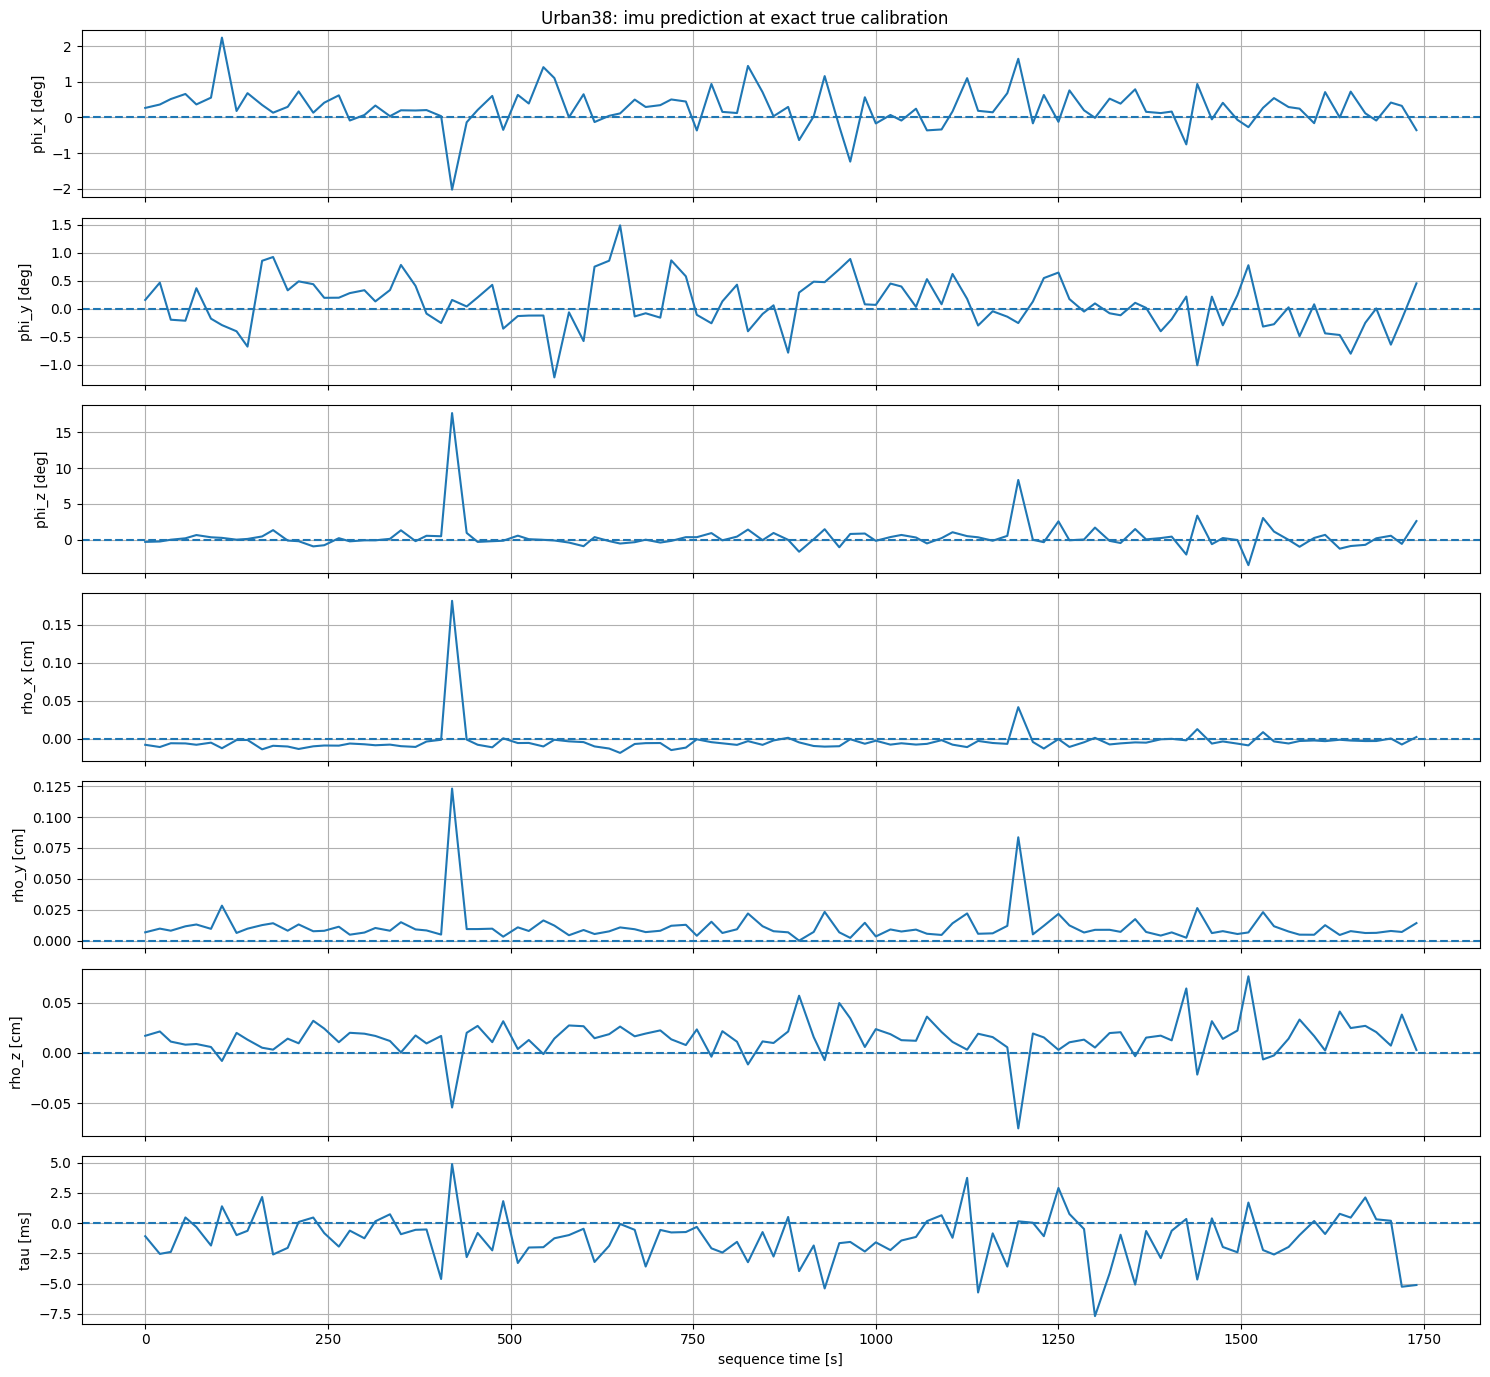

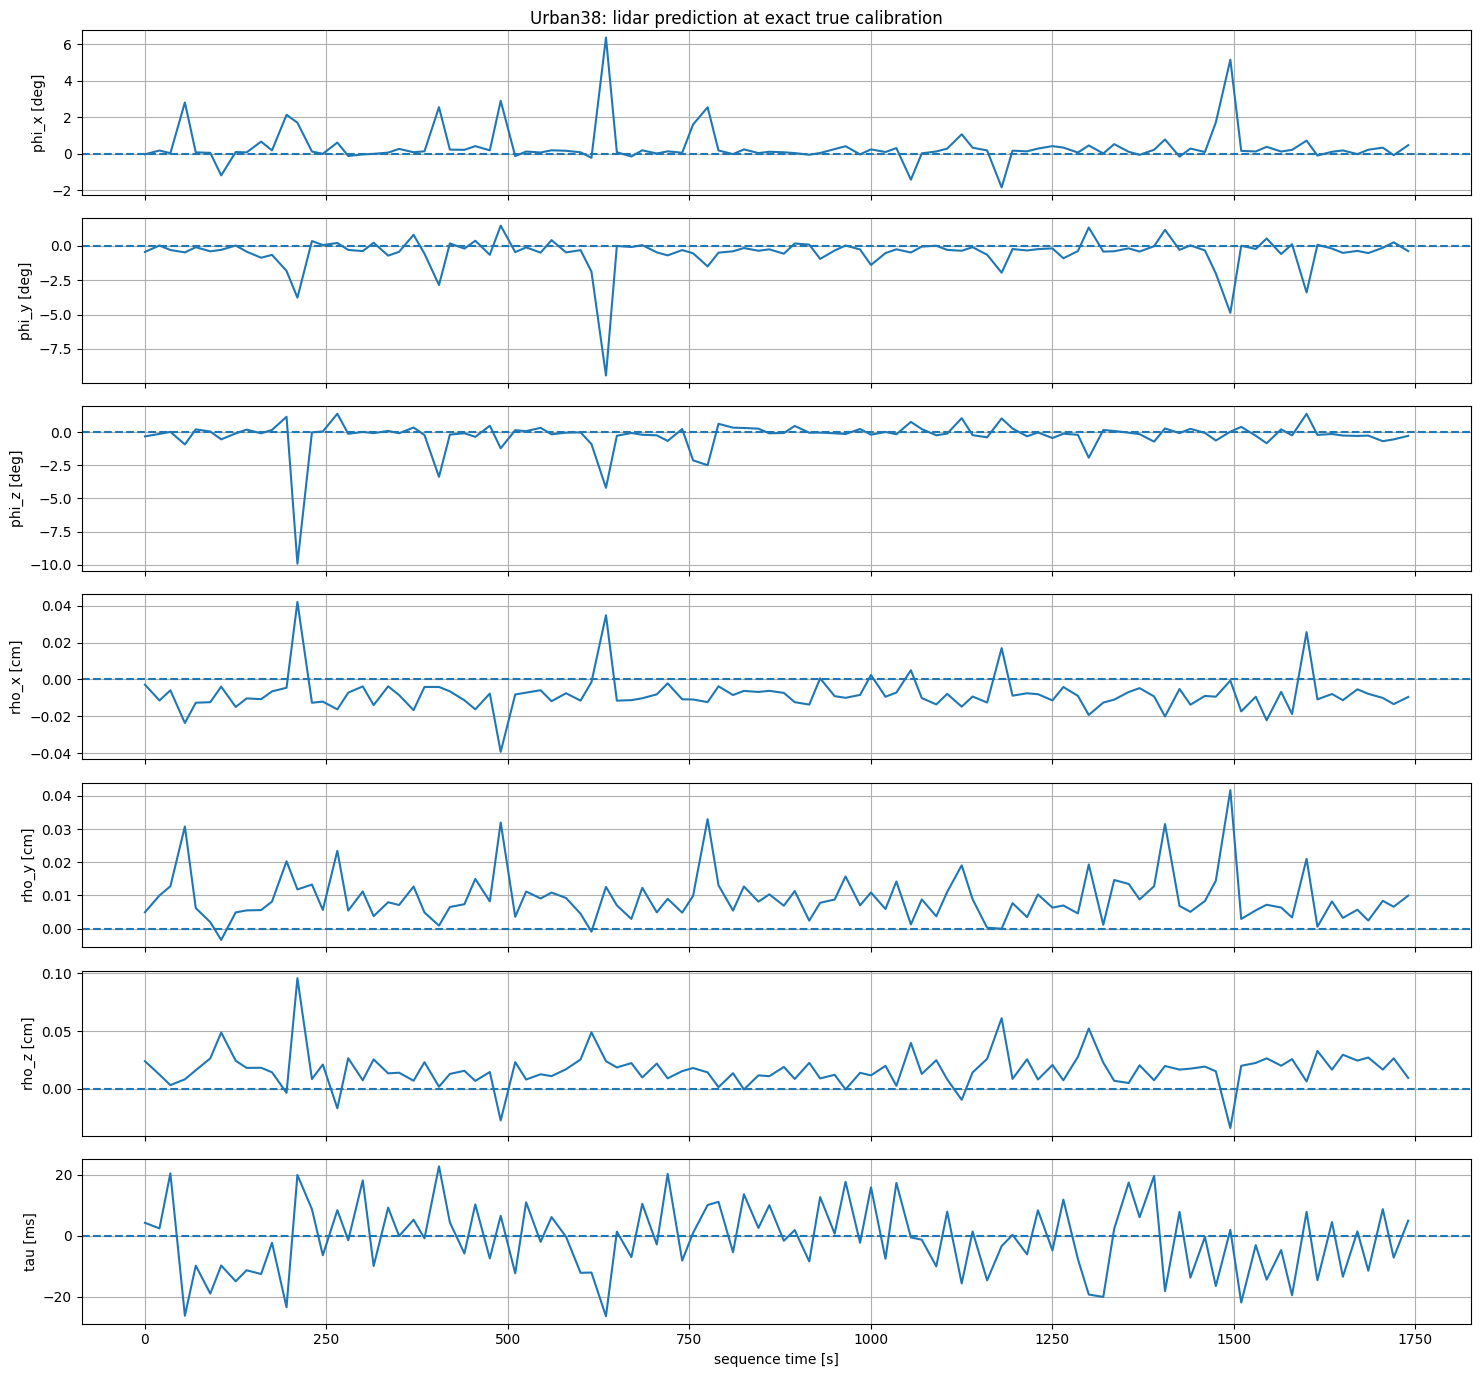

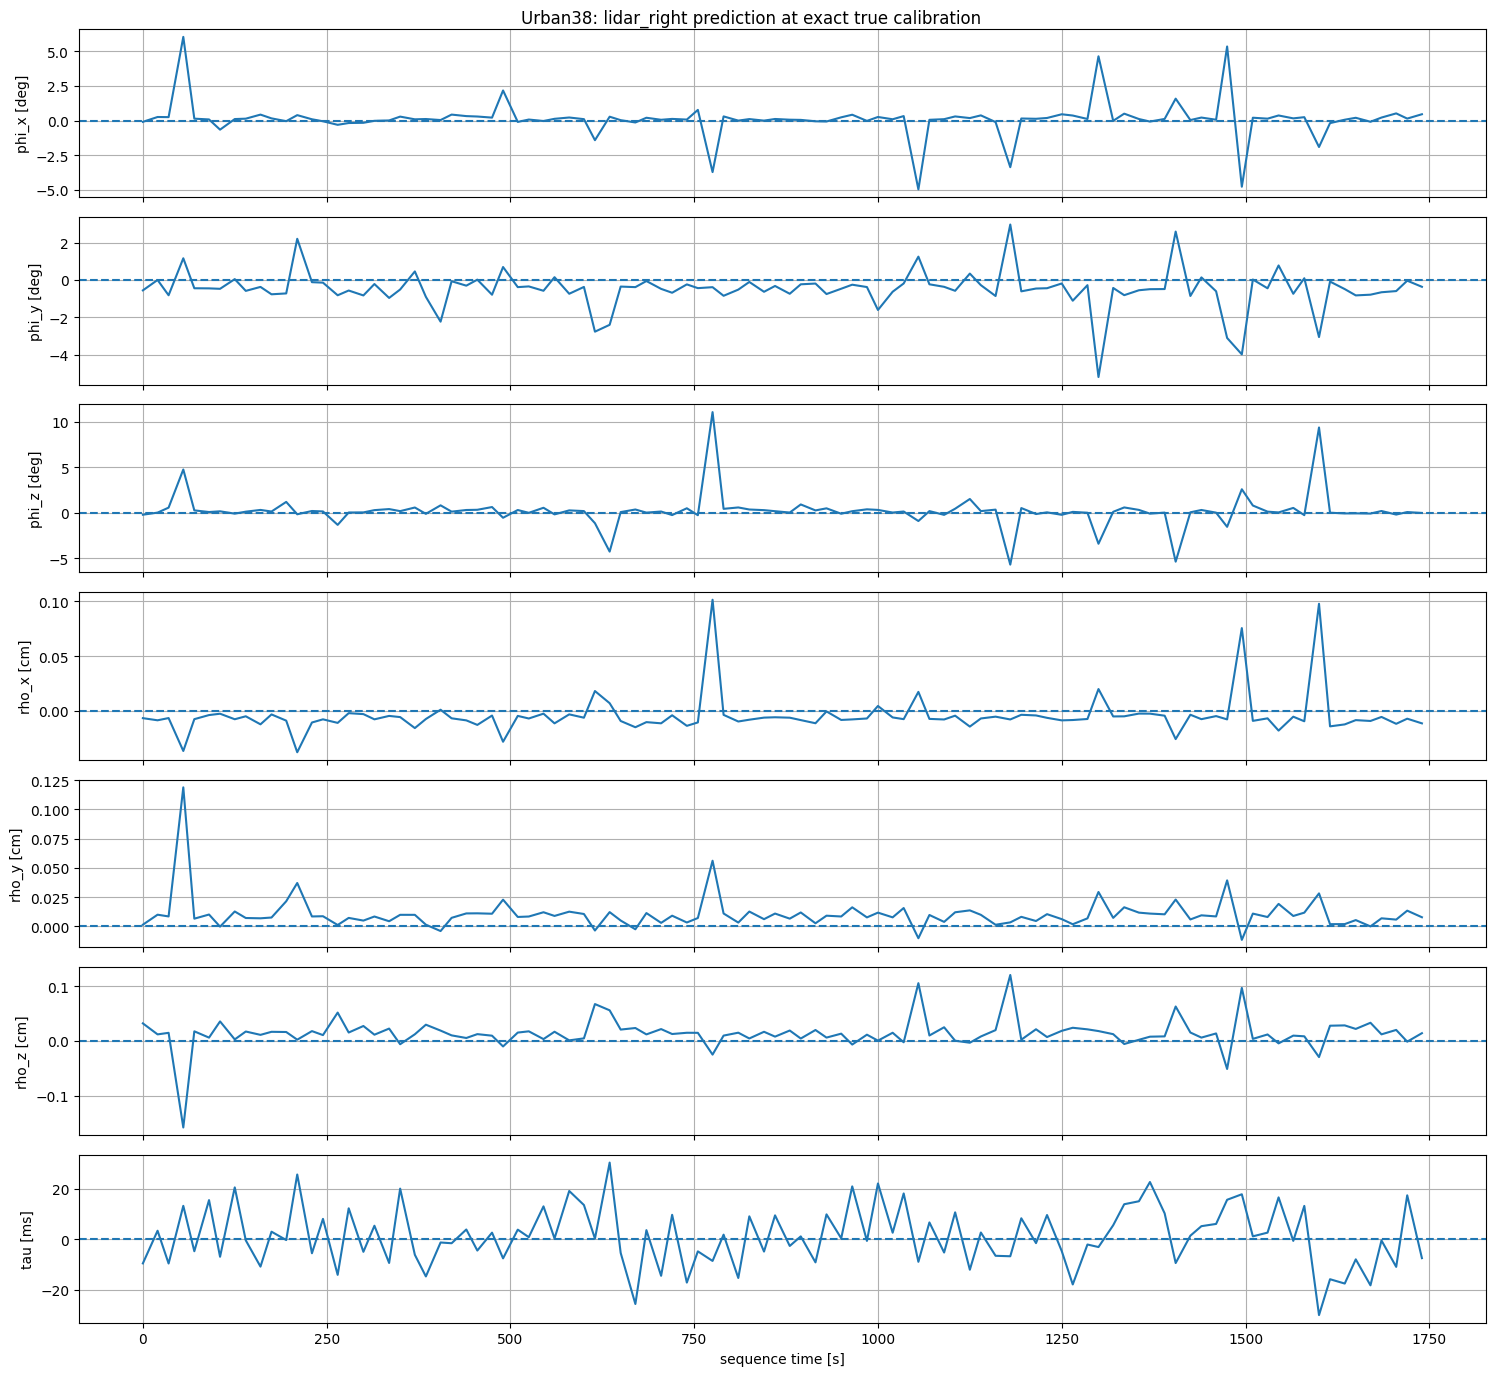

In [80]:
##################################################
# Exact-truth fixed-point diagnostic
#
# Current calibration = true calibration.
# Correct network output is exactly zero.
##################################################

FIXED_POINT_NUM_WINDOWS = min(100, len(rollout_indices))

fixed_point_positions = np.unique(
    np.linspace(
        0,
        len(rollout_indices) - 1,
        FIXED_POINT_NUM_WINDOWS,
    ).round().astype(int)
)

fixed_point_indices = np.asarray(rollout_indices)[fixed_point_positions]

fixed_point_results = {
    calibration_key: {
        "delta_xi": [],
        "delta_tau": [],
    }
    for calibration_key in CALIBRATION_KEYS
}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(
            collate_windows([rollout_dataset[int(dataset_index)]]),
            DEVICE,
            dtype=MODEL_DTYPE,
        )

        exact_true_calibration = {
            calibration_key: CalibrationState(
                transform=state.transform.clone(),
                time_offset=state.time_offset.clone(),
            )
            for calibration_key, state in window.current_calibration.items()
        }

        result = window_step(
            window,
            calibration=exact_true_calibration,
        )

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(
                prediction.delta_xi[0].detach().cpu()
            )

            fixed_point_results[calibration_key]["delta_tau"].append(
                prediction.delta_tau[0, 0].detach().cpu()
            )


for calibration_key in fixed_point_results:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(
        fixed_point_results[calibration_key]["delta_xi"]
    ).numpy()

    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(
        fixed_point_results[calibration_key]["delta_tau"]
    ).numpy()


##################################################
# Numerical summary
##################################################

component_names = (
    "phi_x",
    "phi_y",
    "phi_z",
    "rho_x",
    "rho_y",
    "rho_z",
    "tau",
)

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)
print("Correct prediction for every component is zero.")
print()

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]

    prediction = np.concatenate(
        [
            result["delta_xi"],
            result["delta_tau"][:, None],
        ],
        axis=1,
    )

    print(calibration_key)
    print(
        f"{'component':8s}"
        f"{'mean':>16s}"
        f"{'mean |x|':>16s}"
        f"{'RMSE':>16s}"
        f"{'std':>16s}"
        f"{'range':>16s}"
    )

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values = np.rad2deg(values)
            unit = "deg"

        elif component_index < 6:
            values = 100.0 * values
            unit = "cm"

        else:
            values = 1000.0 * values
            unit = "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(
            f"{component_name:8s}"
            f"{mean:+12.6f} {unit:3s}"
            f"{mean_abs:12.6f} {unit:3s}"
            f"{rmse:12.6f} {unit:3s}"
            f"{std:12.6f} {unit:3s}"
            f"{value_range:12.6f} {unit:3s}"
        )

    print()


##################################################
# Plot residual update at exact truth
##################################################

fixed_point_times_s = fixed_point_positions * windowing_config.window_stride_s

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]

    prediction = np.concatenate(
        [
            result["delta_xi"],
            result["delta_tau"][:, None],
        ],
        axis=1,
    )

    fig, axes = plt.subplots(
        7,
        1,
        figsize=(15, 14),
        sharex=True,
    )

    for component_index, component_name in enumerate(component_names):
        if component_index < 3:
            values = np.rad2deg(
                prediction[:, component_index]
            )
            unit = "deg"

        elif component_index < 6:
            values = 100.0 * prediction[:, component_index]
            unit = "cm"

        else:
            values = 1000.0 * prediction[:, component_index]
            unit = "ms"

        axes[component_index].plot(
            fixed_point_times_s,
            values,
        )

        axes[component_index].axhline(
            0.0,
            linestyle="--",
        )

        axes[component_index].set_ylabel(
            f"{component_name} [{unit}]"
        )

        axes[component_index].grid(True)

    axes[-1].set_xlabel(
        "sequence time [s]"
    )

    fig.suptitle(
        f"{SEQUENCE_NAME}: {calibration_key} prediction at exact true calibration"
    )

    fig.tight_layout()
    plt.show()